# Встреча 2. План теста

**Легенда.** Встреча 1 закончилась вердиктом «тестируем»: решение по конверсии принимаем против точки безубыточности $\theta_{BE}$ = 0.246 п.п., α = 0.5, 105 тыс. пользователей, 14 дней. Теперь превращаем эти числа в план теста нового чекаута: что рандомизируем, что именно доказываем, что такой тест способен увидеть, честен ли критерий на наших данных, какие метрики за что отвечают, хватает ли 14 дней guardrail и как сделать тест короче. Итог — дизайн-док: по нему на встрече 3 проверим, что тест запущен так, как задуман.

Опираемся на Kohavi, Tang, Xu (*Trustworthy Online Controlled Experiments*), CUPED (Deng et al., 2013), линеаризацию (Budylin et al., 2018) и фреймворк правил запуска Spotify (Schultzberg et al., 2024). Ссылки — в конце ноутбука.

**Разделы**

1. Единица рандомизации и единица анализа.
2. Что доказываем: вид теста.
3. Размер выборки, MDE и длительность.
4. Правило решения на симуляции и A/A на своих данных.
5. Критерий под тип метрики, SRM.
6. Роли метрик и поправки; хватает ли 14 дней guardrail.
7. Ускорение: стратификация, CUPED, линеаризация, выбросы.
8. Дизайн-док.
9. Итоги.

По ходу встречаются вопросы для обсуждения: сначала подумайте и обсудите, потом раскройте ответ.

In [1]:
import ast
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from statsmodels.stats.proportion import proportion_confint

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
PURPLE, ORANGE = '#8172B3', '#DD8452'


def sp(x) -> str:
    # Число с пробелами между разрядами: 105 000
    return f'{x:,.0f}'.replace(',', ' ')


def z_crit(alpha: float, sides: int) -> float:
    # Критическое значение: z_{1-α} для односторонней альтернативы, z_{1-α/2} для двусторонней
    return stats.norm.ppf(1 - alpha / sides)


def masked_mean_var(x: np.ndarray, mask: np.ndarray):
    # Среднее, дисперсия и размер по строкам x только по наблюдениям из mask
    n = mask.sum(axis=1)
    mean = (x * mask).sum(axis=1) / n
    var = ((x ** 2 * mask).sum(axis=1) - n * mean ** 2) / (n - 1)
    return mean, var, n


def z_pvalue(delta: np.ndarray, se: np.ndarray) -> np.ndarray:
    return 2 * stats.norm.sf(np.abs(delta / se))


def rate_with_ci(rejected: np.ndarray):
    low, high = proportion_confint(rejected.sum(), rejected.size, method='wilson')
    return float(rejected.mean()), float(low), float(high)


def plot_rates(ax, rates: dict, title: str, reference: float | None = 0.05) -> None:
    # Доли отклонений H0 с 95% ДИ: одна точка на метод
    names = list(rates)[::-1]
    values = np.array([rate_with_ci(rates[name]) for name in names])
    ax.errorbar(values[:, 0], names, xerr=[values[:, 0] - values[:, 1], values[:, 2] - values[:, 0]],
                fmt='o', color=BLUE, capsize=4)
    if reference is not None:
        ax.axvline(reference, color=RED, linestyle='--', label=f'Заявленный уровень {reference:.0%}')
        ax.legend(loc='lower right')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
    ax.set_title(title)

### Параметры кейса

`FROM_MEETING_1` — выход встречи 1, словарь `VERDICT`. Ячейка читает его из исполненного ноутбука встречи 1 (`../01. Стоит ли тестировать и на чём измерять/lesson.ipynb`); если файла рядом нет (например, в Colab), берёт те же значения из запасного словаря. `DESIGN` — решения, которые принимаем сегодня вместе с владельцем продукта. Поменяли значения здесь — пересчитается весь ноутбук.

In [2]:
MEETING_1 = Path('../01. Стоит ли тестировать и на чём измерять/lesson.ipynb')
# Копия VERDICT встречи 1 — синхронизировать при изменении встречи 1
VERDICT_FALLBACK = {'alpha': 0.5, 'break_even_pp': 0.246, 'n_b': 21_000, 'n_total': 105_000,
                    'days': 14, 'decision': 'тестируем'}


def read_verdict(path: Path) -> dict | None:
    # VERDICT — результат ячейки встречи 1, где он собирается
    try:
        nb = json.loads(path.read_text(encoding='utf-8'))
    except (OSError, ValueError):
        return None
    for cell in nb['cells']:
        if cell['cell_type'] == 'code' and 'VERDICT = {' in ''.join(cell['source']):
            for out in cell.get('outputs', []):
                if out.get('output_type') == 'execute_result':
                    return ast.literal_eval(''.join(out['data']['text/plain']))
    return None


FROM_MEETING_1 = read_verdict(MEETING_1)
print('VERDICT встречи 1:', 'прочитан из ноутбука' if FROM_MEETING_1 else 'запасные значения')
FROM_MEETING_1 = FROM_MEETING_1 or VERDICT_FALLBACK
print(FROM_MEETING_1)

DESIGN = {
    'share_b': 0.20,           # доля трафика на новый чекаут
    'daily_users': 7_500,      # плановый трафик чекаута в день (тот же, что во встрече 1)
    'power': 0.80,             # мощность OEC
    'alpha': 0.05,             # α для guardrail и вторичных метрик — классический, не из финмодели
    'mde_arpu_rel': 0.02,      # ARPU: +2% — для расчёта CUPED
    'ni_payment_error': 0.002, # guardrail: ошибки оплаты растут не более чем на 0.2 п.п. (≈10% от базы 2%)
    'min_weeks': 1,            # длительность — целые недели, не меньше одной
}

ALPHA_OEC = FROM_MEETING_1['alpha']
BE = FROM_MEETING_1['break_even_pp'] / 100
ALPHA = DESIGN['alpha']
SHARE_B, POWER, DAILY_USERS = DESIGN['share_b'], DESIGN['power'], DESIGN['daily_users']

VERDICT встречи 1: прочитан из ноутбука
{'alpha': 0.5, 'break_even_pp': 0.246, 'n_b': 21000, 'n_total': 105000, 'days': 14, 'decision': 'тестируем'}


Данные — `../data/checkout_ab.csv`: одна строка — один пользователь чекаута за 14 дней, сплит 80/20, предпериод 28 дней (`orders_prev28`, `revenue_prev28`). Тест мы ещё **планируем**, поэтому для оценок берём только контроль A как «историю». Группу B не смотрим: эффект оценим на встрече 6. Очистка — по правилу встречи 3 (там разберём, откуда дефекты): убираем полные дубли строк и пользователей, которые попали в обе группы.

In [3]:
DATA_PATH = Path('../data/checkout_ab.csv')
DATA_URL = 'https://raw.githubusercontent.com/Alberelloo/AITH-2026-Hypothesis-Testing-Workshop/main/data/checkout_ab.csv'
raw = pd.read_csv(DATA_PATH if DATA_PATH.exists() else DATA_URL)

df = raw.drop_duplicates()
in_both = df.groupby('user_id')['group'].nunique().loc[lambda s: s > 1].index
df = df[~df['user_id'].isin(in_both)].reset_index(drop=True)

base = df[df['group'] == 'A'].reset_index(drop=True)   # «история»: только контроль
P_A = base['converted'].mean()
rng_case = np.random.default_rng(2026)                 # все случайные деления данных кейса

print(f"Пользователей: {sp(len(df))} (A: {sp((df['group'] == 'A').sum())}, B: {sp((df['group'] == 'B').sum())}); "
      f"в день: {sp(len(df) / df['date'].nunique())}, в плане — {sp(DAILY_USERS)}")
print(f'Конверсия контроля: {P_A:.4f}; ARPU: {sp(base["revenue"].mean())} ₽; ошибки оплаты: {base["payment_error"].mean():.4f}')
base.head()

Пользователей: 104 960 (A: 83 878, B: 21 082); в день: 7 497, в плане — 7 500
Конверсия контроля: 0.6987; ARPU: 2 604 ₽; ошибки оплаты: 0.0200


,user_id,date,group,converted,revenue,checkout_time_sec,payment_error,orders_prev28,revenue_prev28
0,7480367,2026-09-20,A,1,997.12,261.9,0,2,3817.54
1,9280410,2026-09-12,A,1,23649.07,55.2,0,7,109549.40
2,9684298,2026-09-13,A,1,2037.39,123.9,0,2,3051.12
3,1961867,2026-09-12,A,1,1761.46,45.4,0,2,2938.46
4,9825369,2026-09-09,A,1,1285.30,67.4,0,6,19640.79


## 1. Единица рандомизации и единица анализа

* **Единица рандомизации** — то, на что мы «бросаем монетку». В чекауте это пользователь: группа = хеш(`user_id` + соль теста).
* **Единица анализа** — то, по чему считаем метрику и её дисперсию.

Если они совпадают, наблюдения независимы и работают обычные z- и t-тесты. Конверсия, ARPU, время на чекауте — метрики на пользователя, с ними всё в порядке. Если рандомизировать можно только крупнее — магазин, город, интервал времени, — это кластерный дизайн, встреча 5. В дизайн-доке пишем обе единицы явно.

**Вопрос.** Рандомизируем пользователей. Средний чек = Σ выручки / Σ заказов, и аналитик сравнивает его обычным t-тестом по заказам: одна строка — один заказ. Что не так?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Единица анализа (заказ) не совпадает с единицей рандомизации (пользователь). Заказы одного пользователя похожи друг на друга: у «китов» все чеки большие. Наблюдения зависимы, а t-тест считает их независимыми, поэтому SE занижена и тест слишком часто находит эффект.

Лечится дельта-методом или линеаризацией: метрика отношения превращается в метрику на пользователя (раздел 7). На похожей симуляции с CTR наивный тест «по показам» ошибается в ≈ 19% A/A-тестов вместо 5%.

</details>

## 2. Что доказываем: вид теста

$\mu$ — истинная разность «B − A» (для метрик «меньше — лучше» знаки меняются), $\Delta$ — допуск, $\theta_{BE}$ — порог безубыточности.

| Вид | Нулевая гипотеза | Альтернатива | Когда |
|---|---|---|---|
| Superiority | μ ≤ 0 (двусторонний: μ = 0) | μ > 0 (μ ≠ 0) | новое лучше; граница гипотезы — **ноль** |
| Non-inferiority | μ ≤ −Δ | μ > −Δ | guardrail: хуже не более чем на допуск Δ |
| Equivalence | μ ≤ −Δ или μ ≥ Δ | −Δ < μ < Δ | миграция, рефакторинг: «ничего не изменилось», TOST |
| Против порога безубыточности | μ ≤ θ_BE | μ > θ_BE | внедрение окупается; θ_BE — из финмодели встречи 1 |

Встреча 1 выбрала последний вид: α = 0.5 против $\theta_{BE}$ = 0.246 п.п. При α = 0.5 критическое значение $z_{1-\alpha}$ = 0, и правило звучит просто: **внедряем, если оценка $\hat p_B - \hat p_A$ выше 0.246 п.п.** Такой α выбрала финмодель: ошибки по обе стороны BE стоят примерно одинаково, и риск-нейтральное решение — «оценка выше BE → внедряем».

На языке доверительных интервалов успех каждого вида выглядит так:

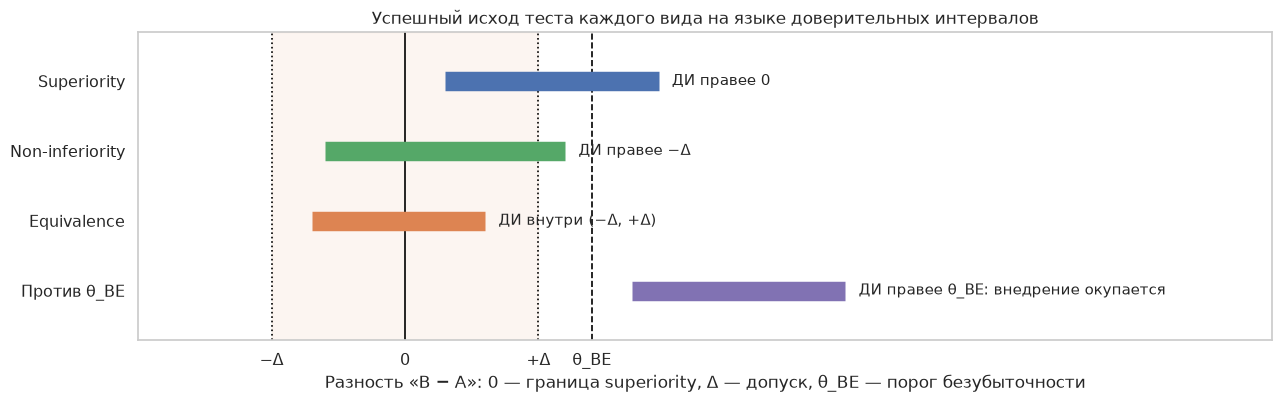

In [4]:
margin, theta_be = 1.0, 1.4
examples = [
    ('Против θ_BE', (1.7, 3.3), PURPLE, 'ДИ правее θ_BE: внедрение окупается'),
    ('Equivalence', (-0.7, 0.6), ORANGE, 'ДИ внутри (−Δ, +Δ)'),
    ('Non-inferiority', (-0.6, 1.2), GREEN, 'ДИ правее −Δ'),
    ('Superiority', (0.3, 1.9), BLUE, 'ДИ правее 0'),
]
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.axvspan(-margin, margin, color=ORANGE, alpha=0.08)
for x, style in ((-margin, ':'), (0, '-'), (margin, ':'), (theta_be, '--')):
    ax.axvline(x, color='black', linestyle=style, linewidth=1.2)
for row, (name, (left, right), color, note) in enumerate(examples):
    ax.plot([left, right], [row, row], color=color, linewidth=14, solid_capstyle='butt')
    ax.text(right + 0.1, row, note, va='center', fontsize=11)
ax.set_yticks(range(len(examples)), labels=[e[0] for e in examples])
ax.set_xticks([-margin, 0, margin, theta_be], labels=['−Δ', '0', '+Δ', 'θ_BE'])
ax.set_xlabel('Разность «B − A»: 0 — граница superiority, Δ — допуск, θ_BE — порог безубыточности')
ax.set_xlim(-2, 6.5)
ax.set_ylim(-0.7, len(examples) - 0.3)
ax.grid(False)
ax.set_title('Успешный исход теста каждого вида на языке доверительных интервалов')
plt.tight_layout()
plt.show()

В разговоре о дизайне легко смешать три разных числа:

* **MDE** — параметр мощности: эффект, который тест заметит с вероятностью $1 - \beta$. В гипотезу он не входит.
* **Δ** — допуск non-inferiority и equivalence: насколько хуже ещё приемлемо. Это граница гипотезы.
* **θ_BE** — граница гипотезы, если решаем «окупится ли». Тогда размер выборки считается под разность $\text{MDE} - \theta_{BE}$.

**Вопрос.** В черновике дизайн-дока: «guardrail — доля ошибок оплаты, MDE = +0.2 п.п.». Что здесь перепутано и почему это важно?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

+0.2 п.п. — это не MDE, а **допуск Δ** non-inferiority: граница нулевой гипотезы «ошибки выросли на 0.2 п.п. или больше». MDE у guardrail — истинная разность, при которой мы хотим доказать «не хуже» с заданной мощностью; обычно берут 0, то есть «чекаут ничего не ломает».

Разница не терминологическая. Если записать +0.2 п.п. как MDE, получится superiority-тест «ищем рост ошибок на 0.2 п.п.»: незначимый результат там читают как «всё в порядке», хотя тест просто ничего не нашёл. Non-inferiority требует обратного — **доказать**, что рост меньше допуска. Для этого нужна мощность, и в разделе 6 мы увидим, что 14 дней её не дают.

</details>

## 3. Размер выборки, MDE и длительность

Пусть $w_A$ и $w_B = 1 - w_A$ — доли трафика, $\sigma_A^2$ и $\sigma_B^2$ — дисперсии метрики на пользователя (для доли $\sigma^2 = p(1-p)$), $\delta$ — истинный эффект, $\mu_0$ — граница нулевой гипотезы (0 для superiority, $\theta_{BE}$ для решения встречи 1), $s$ — **сторонность** альтернативы (1 или 2). Общий размер выборки:

$$
N = \frac{(z_{1-\alpha/s} + z_{1-\beta})^2 \cdot V}{(\delta - \mu_0)^2}
$$

$$
V = \frac{\sigma_A^2}{w_A} + \frac{\sigma_B^2}{w_B}
$$

MDE — та же формула, решённая относительно $\delta$ при заданном $N$:

$$
\text{MDE} = \mu_0 + (z_{1-\alpha/s} + z_{1-\beta}) \cdot SE
$$

$$
SE = \sqrt{\frac{\sigma_A^2}{w_A N} + \frac{\sigma_B^2}{w_B N}}
$$

Сторонность — решение дизайна, а не деталь формулы: считать MDE с $z_{1-\alpha}$, а $N$ с $z_{1-\alpha/2}$ — значит описывать два разных теста. Длительность округляем вверх до целых недель: в будни и выходные покупают разные люди.

$N$ = 105 тыс. и 14 дней уже выбрала встреча 1. Здесь мы их **не пересчитываем**, а проверяем обратным ходом: какой эффект такой тест видит с мощностью 0.8.

In [5]:
def var_prop(p):
    return p * (1 - p)


def n_total(var_a: float, var_b: float, mde: float, null: float = 0.0, share_b: float = SHARE_B,
            alpha: float = ALPHA, power: float = POWER, sides: int = 2) -> int:
    # Общий размер выборки (обе группы), округлённый вверх
    z = z_crit(alpha, sides) + stats.norm.ppf(power)
    return math.ceil(z ** 2 / (mde - null) ** 2 * (var_a / (1 - share_b) + var_b / share_b))


def duration(n: int, daily_users: float = DAILY_USERS, min_weeks: int = DESIGN['min_weeks']) -> tuple[int, int]:
    # (дней трафика, недель): недели — вверх до целого и не меньше min_weeks
    days = math.ceil(n / daily_users)
    return days, max(min_weeks, math.ceil(days / 7))


# Обратная задача: какой эффект тест встречи 1 видит с мощностью 80%?
N_PLAN = FROM_MEETING_1['n_total']
SE1 = math.sqrt(var_prop(P_A) * (1 / ((1 - SHARE_B) * N_PLAN) + 1 / (SHARE_B * N_PLAN)))
MDE = BE + (z_crit(ALPHA_OEC, 1) + stats.norm.ppf(POWER)) * SE1
N_OEC = n_total(var_prop(P_A), var_prop(P_A + MDE), MDE, null=BE, alpha=ALPHA_OEC, sides=1)
OEC_DAYS, OEC_WEEKS = duration(N_OEC)
DAYS, WEEKS = FROM_MEETING_1['days'], duration(N_PLAN)[1]
print(f'SE разности при N = {sp(N_PLAN)}: {100 * SE1:.3f} п.п.; MDE (мощность 80%) = {100 * MDE:.3f} п.п.')
print(f'Обратный ход: N = {sp(N_OEC)}, n_B = {sp(N_OEC * SHARE_B)}, {OEC_DAYS} дней; '
      f'встреча 1: n_B = {sp(FROM_MEETING_1["n_b"])}, {FROM_MEETING_1["days"]} дней')

SE разности при N = 105 000: 0.354 п.п.; MDE (мощность 80%) = 0.544 п.п.
Обратный ход: N = 104 126, n_B = 20 825, 14 дней; встреча 1: n_B = 21 000, 14 дней


Тест встречи 1 с мощностью 80% видит эффект ≈ 0.54 п.п. = 0.246 + (0 + 0.84) · 0.354. Обратный ход по формуле даёт те же 14 дней.

Теперь цена решений дизайна: меняем по одному параметру и смотрим, сколько стоил бы другой тест.

**Вопрос.** Владелец продукта говорит: «Хотим ловить рост конверсии на 1%». Что нужно уточнить, прежде чем считать N?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Единицы. «+1%» — это либо +1 п.п. (70% → 71%), либо +1% от базы (70% → 70.7%). $N$ пропорционален $1/\delta^2$, поэтому относительная трактовка требует примерно в $(1/0.7)^2$ ≈ 2 раза больше трафика: в таблице ниже 28 дней вместо 14.

Ещё два уточнения: против чего доказываем (ноль или порог безубыточности) и что делаем при ухудшении (односторонняя или двусторонняя альтернатива). В доке пишем и число, и единицы, и сторонность.

</details>

In [6]:
variants = {
    'встреча 1: против θ_BE, α = 0.5, односторонний': dict(mde=MDE, null=BE, alpha=ALPHA_OEC, sides=1),
    'то же, сплит 50/50': dict(mde=MDE, null=BE, alpha=ALPHA_OEC, sides=1, share_b=0.5),
    'стандарт: против 0, α = 0.05, двусторонний, тот же MDE': dict(mde=MDE),
    'стандарт, MDE +1 п.п.': dict(mde=0.01),
    'стандарт, MDE +1 п.п., односторонний': dict(mde=0.01, sides=1),
    'стандарт, относительный MDE +1% от P_A': dict(mde=0.01 * P_A),
}
rows = []
for name, params in variants.items():
    mde = params['mde']
    n = n_total(var_prop(P_A), var_prop(P_A + mde), **params)
    days, weeks = duration(n)
    rows.append({'вариант': name, 'MDE, п.п.': round(100 * mde, 3), 'N': n,
                 'n_B': round(n * params.get('share_b', SHARE_B)), 'дней': days, 'недель': weeks})
design_table = pd.DataFrame(rows).set_index('вариант')

N_of = design_table['N'].to_list()
print(f'80/20 дороже 50/50 в {N_of[0] / N_of[1]:.2f} раза; стандартный тест на тот же MDE дороже в {N_of[2] / N_of[0]:.1f} раза; '
      f'односторонний дешевле двустороннего на {1 - N_of[4] / N_of[3]:.0%}; относительный MDE дороже абсолютного в {N_of[5] / N_of[3]:.2f} раза')
design_table

80/20 дороже 50/50 в 1.56 раза; стандартный тест на тот же MDE дороже в 3.3 раза; односторонний дешевле двустороннего на 21%; относительный MDE дороже абсолютного в 2.06 раза


,"MDE, п.п.",N,n_B,дней,недель
вариант,,,,,
"встреча 1: против θ_BE, α = 0.5, односторонний",0.544,104126,20825,14,2
"то же, сплит 50/50",0.544,66851,33426,9,2
"стандарт: против 0, α = 0.05, двусторонний, тот же MDE",0.544,346163,69233,47,7
"стандарт, MDE +1 п.п.",1.000,101679,20336,14,2
"стандарт, MDE +1 п.п., односторонний",1.000,80092,16018,11,2
"стандарт, относительный MDE +1% от P_A",0.699,209302,41860,28,4


**Вопрос.** Тест встречи 1 видит 0.54 п.п. за 14 дней, а стандартный тест на тот же эффект шёл бы 47 дней. Почему втрое дешевле — и не обман ли это?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Это ответ на другой вопрос: не «докажите, что эффект есть», а «оценка выше порога окупаемости?». Стандарт требует, чтобы эффект 0.54 п.п. отстоял от **нуля** на $z_{0.975} + z_{0.8}$ ≈ 2.8 SE, то есть SE ≤ 0.544 / 2.8 ≈ 0.19 п.п. Встреча 1 требует, чтобы он отстоял от **θ_BE** на $z_{0.5} + z_{0.8}$ ≈ 0.84 SE. Но от θ_BE до 0.544 всего 0.298 п.п., то есть SE ≤ 0.298 / 0.84 ≈ 0.35 п.п. $N$ обратно пропорционален SE²: (0.35 / 0.19)² ≈ 3.3.

Обмана нет, пока мы честно называем результат. Финмодель встречи 1 посчитала, что ошибка «внедрили при эффекте чуть ниже BE» стоит немного, а лишние недели теста — дорого. Но в отчёте нельзя писать «эффект доказан с α = 0.05»: правило с таким порогом этого не проверяет.

</details>

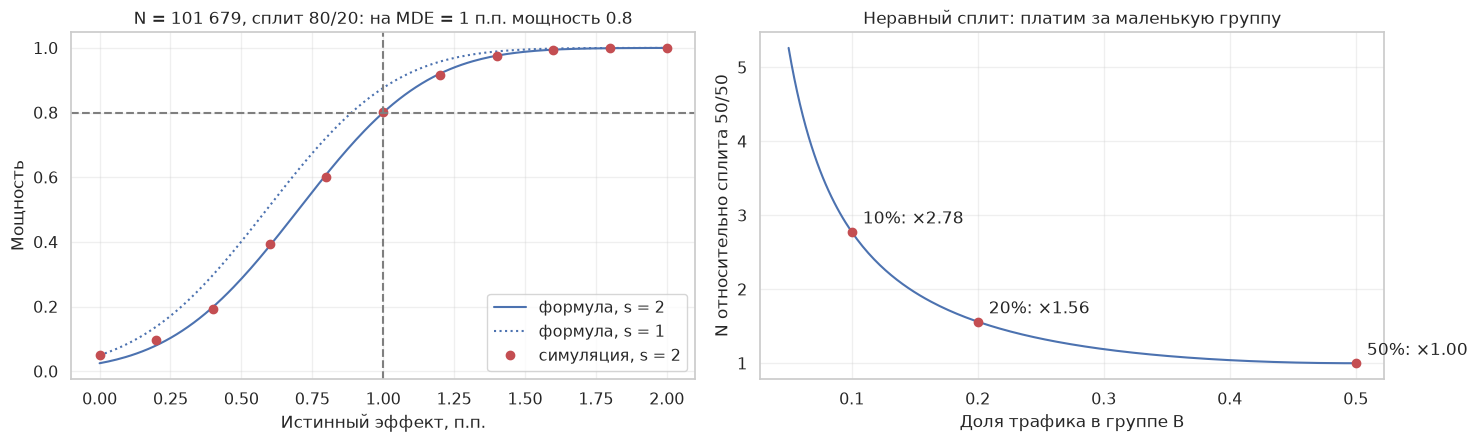

In [7]:
# Мощность по формуле и в биномиальной симуляции для стандартного дизайна «MDE +1 п.п., двусторонний, 80/20»
N_BASE = design_table.loc['стандарт, MDE +1 п.п.', 'N']
n_b_base = round(N_BASE * SHARE_B)
n_a_base = N_BASE - n_b_base
rng = np.random.default_rng(2)
effects = np.linspace(0, 0.02, 11)
sim_power = []
for d in effects:
    x_a, x_b = rng.binomial(n_a_base, P_A, 4_000), rng.binomial(n_b_base, P_A + d, 4_000)
    p_pool = (x_a + x_b) / N_BASE
    z = (x_b / n_b_base - x_a / n_a_base) / np.sqrt(p_pool * (1 - p_pool) * (1 / n_a_base + 1 / n_b_base))
    sim_power.append(np.mean(np.abs(z) > z_crit(ALPHA, 2)))
grid = np.linspace(0, 0.02, 200)
se = np.sqrt(P_A * (1 - P_A) / n_a_base + (P_A + grid) * (1 - P_A - grid) / n_b_base)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
axes[0].plot(grid * 100, stats.norm.sf(z_crit(ALPHA, 2) - grid / se), color=BLUE, label='формула, s = 2')
axes[0].plot(grid * 100, stats.norm.sf(z_crit(ALPHA, 1) - grid / se), color=BLUE, ls=':', label='формула, s = 1')
axes[0].plot(effects * 100, sim_power, 'o', color=RED, label='симуляция, s = 2')
axes[0].axhline(POWER, color=GRAY, ls='--')
axes[0].axvline(1.0, color=GRAY, ls='--')
axes[0].set_xlabel('Истинный эффект, п.п.')
axes[0].set_ylabel('Мощность')
axes[0].set_title(f'N = {sp(N_BASE)}, сплит 80/20: на MDE = 1 п.п. мощность 0.8')
axes[0].legend(loc='lower right')

shares = np.linspace(0.05, 0.5, 200)
cost = (1 / shares + 1 / (1 - shares)) / 4
axes[1].plot(shares, cost, color=BLUE)
for w in (0.1, 0.2, 0.5):
    c = (1 / w + 1 / (1 - w)) / 4
    axes[1].scatter([w], [c], color=RED, zorder=3)
    axes[1].annotate(f'{w:.0%}: ×{c:.2f}', (w, c), textcoords='offset points', xytext=(8, 6))
axes[1].set_xlabel('Доля трафика в группе B')
axes[1].set_ylabel('N относительно сплита 50/50')
axes[1].set_title('Неравный сплит: платим за маленькую группу')
plt.tight_layout()
plt.show()

Что видно:

* **Неравный сплит.** $N$ пропорционален $1/w_A + 1/w_B$: 4 при 50/50 и 6.25 при 80/20, то есть ×1.56. Это цена осторожности: 104 тыс. пользователей вместо 67 тыс. (14 дней трафика вместо 9). В календаре разницы нет: с округлением до целых недель оба варианта — 2 недели. Так что 50/50 за те же 14 дней дал бы больше мощности, но не более короткий тест.
* **Сторонность.** Односторонний тест дешевле на ≈ 21%, но не видит ухудшения. Если вопрос «есть ли эффект» — двусторонний. Если решение денежное, как на встрече 1, — односторонний против $\theta_{BE}$. Guardrail — односторонние non-inferiority.
* **Длительность** — целые недели, не меньше одной (`min_weeks` в `DESIGN`), даже если $N$ набирается за 3 дня. Фиксируем её до старта; подглядывание и досрочная остановка — встреча 4.
* Точки симуляции легли на кривую: нормальная аппроксимация для конверсии 70% при таких $N$ работает.

**Итог раздела:** OEC — односторонний z-тест против $\theta_{BE}$ = 0.246 п.п. с α = 0.5; MDE при мощности 0.8 ≈ 0.54 п.п.; сплит 80/20, $N$ ≈ 105 тыс., **14 дней = 2 недели**.

## 4. Правило решения на симуляции и A/A на своих данных

Формула $N$ опирается на нормальную аппроксимацию. Проверим, что правило встречи 1 с нашими $N$ и сплитом ведёт себя так, как задумано. Статистика z-теста для двух долей:

$$
z = \frac{\hat p_B - \hat p_A - \mu_0}{SE}
$$

При $\mu_0$ = 0 доли под $H_0$ равны, и дисперсию оцениваем по объединённой доле $\hat p = (x_A + x_B) / (n_A + n_B)$:

$$
SE = \sqrt{\hat p (1 - \hat p) \left(\frac{1}{n_A} + \frac{1}{n_B}\right)}
$$

При $\mu_0 \ne 0$ доли под $H_0$ разные, и дисперсию считаем по каждой группе:

$$
SE = \sqrt{\frac{\hat p_A (1 - \hat p_A)}{n_A} + \frac{\hat p_B (1 - \hat p_B)}{n_B}}
$$

Число конверсий в группе — $\mathrm{Binomial}(n_g, p_g)$, так что тысячи тестов считаются мгновенно.

In [8]:
def z_test_props(x_a, n_a, x_b, n_b, null: float = 0.0, sides: int = 2):
    # z-тест для двух долей, работает с массивами; при sides=1 альтернатива p_B − p_A > null
    x_a, n_a, x_b, n_b = (np.asarray(v, float) for v in (x_a, n_a, x_b, n_b))
    p_a, p_b = x_a / n_a, x_b / n_b
    if null == 0:
        p_pool = (x_a + x_b) / (n_a + n_b)
        se = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
    else:
        se = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
    z = (p_b - p_a - null) / se
    p_value = 2 * stats.norm.sf(np.abs(z)) if sides == 2 else stats.norm.sf(z)
    return z, p_value

**Вопрос.** Пусть новый чекаут на самом деле ничего не меняет. Как часто правило встречи 1 скажет «внедряем»? Это провал дизайна?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Правило внедряет, если $\hat p_B - \hat p_A$ > 0.246 п.п. При нулевом эффекте оценка разности — нормальная с центром 0 и SE ≈ 0.354 п.п. Порог отстоит от нуля на 0.246 / 0.354 ≈ 0.69 SE, поэтому «внедряем» выпадает в ≈ 24% тестов. Это и есть α правила, если считать его против нуля. Симуляция ниже это подтверждает: ≈ 0.25 (по формуле 0.244).

Это не провал: дизайн отвечает на вопрос о деньгах, а не о существовании эффекта. Внедрить нейтральное изменение стоит только затрат на внедрение, и финмодель их уже учла, когда выбирала α. От реального вреда отдельно страхует guardrail (раздел 6). Цена одна: в отчёте пишем «оценка выше точки безубыточности», а не «эффект доказан».

</details>

эффект 0       доля «внедряем» 0.2458  95% ДИ [0.2399, 0.2518]  (по формуле 0.244)
эффект = θ_BE  доля «внедряем» 0.4993  95% ДИ [0.4924, 0.5062]  (по формуле 0.500)
эффект = MDE   доля «внедряем» 0.8025  95% ДИ [0.7969, 0.8080]  (по формуле 0.800)
Классический A/A, α = 0.05: 0.0495


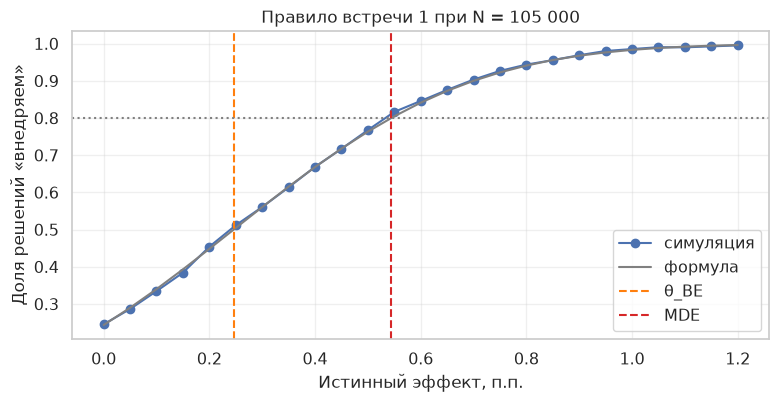

In [9]:
R = 20_000
n_b = FROM_MEETING_1['n_b']
n_a = FROM_MEETING_1['n_total'] - n_b


def rollout_rate(effect: float, R: int = R) -> float:
    # Доля симуляций, где правило встречи 1 говорит «внедряем»
    x_a, x_b = rng_case.binomial(n_a, P_A, R), rng_case.binomial(n_b, P_A + effect, R)
    return (z_test_props(x_a, n_a, x_b, n_b, null=BE, sides=1)[1] < ALPHA_OEC).mean()


checks = {'эффект 0': (0.0, stats.norm.sf(BE / SE1)), 'эффект = θ_BE': (BE, 0.5), 'эффект = MDE': (MDE, POWER)}
RATES = {}
for name, (effect, target) in checks.items():
    RATES[name] = rollout_rate(effect)
    lo, hi = proportion_confint(RATES[name] * R, R, method='wilson')
    print(f'{name:<14} доля «внедряем» {RATES[name]:.4f}  95% ДИ [{lo:.4f}, {hi:.4f}]  (по формуле {target:.3f})')

# Классический A/A: двусторонний тест против 0 на тех же N держит α = 0.05
p_aa = z_test_props(rng_case.binomial(n_a, P_A, R), n_a, rng_case.binomial(n_b, P_A, R), n_b)[1]
print(f'Классический A/A, α = {ALPHA}: {(p_aa < ALPHA).mean():.4f}')

effects = np.linspace(0, 0.012, 25)
plt.figure(figsize=(9, 4))
plt.plot(effects * 100, [rollout_rate(d, 5_000) for d in effects], 'o-', label='симуляция')
plt.plot(effects * 100, stats.norm.cdf((effects - BE) / SE1), color='gray', label='формула')
plt.axvline(BE * 100, color='tab:orange', ls='--', label='θ_BE')
plt.axvline(MDE * 100, color='tab:red', ls='--', label='MDE')
plt.axhline(POWER, color='gray', ls=':')
plt.xlabel('Истинный эффект, п.п.')
plt.ylabel('Доля решений «внедряем»')
plt.title(f'Правило встречи 1 при N = {sp(FROM_MEETING_1["n_total"])}')
plt.legend()
plt.show()

Правило ведёт себя так, как задумано: при нулевом эффекте внедряет в ≈ 24% случаев, при эффекте ровно $\theta_{BE}$ — в половине, при эффекте = MDE — в 80%.

Биномиальная симуляция проверяет формулу, но не наши данные. **A/A на своих данных:** много раз случайно делим контроль 80/20 и прогоняем тот же z-тест. Эффекта нет по построению, поэтому классический тест должен ошибаться в ≈ 5% случаев, а правило встречи 1 — «внедрять» с той долей, которую предсказывает формула для этого $N$.

In [10]:
conv = base['converted'].to_numpy()
R_AA = 2_000
p_classic, p_rule = np.empty(R_AA), np.empty(R_AA)
for r in range(R_AA):
    is_b = rng_case.random(conv.size) < SHARE_B
    args = (conv[~is_b].sum(), (~is_b).sum(), conv[is_b].sum(), is_b.sum())
    p_classic[r] = z_test_props(*args)[1]
    p_rule[r] = z_test_props(*args, null=BE, sides=1)[1]
se_real = math.sqrt(var_prop(P_A) * (1 / ((1 - SHARE_B) * conv.size) + 1 / (SHARE_B * conv.size)))
ALPHA_REAL, RULE_REAL, RULE_EXPECTED = (p_classic < ALPHA).mean(), (p_rule < ALPHA_OEC).mean(), stats.norm.sf(BE / se_real)
print(f'A/A на контроле ({sp(conv.size)} польз.): классический тест {ALPHA_REAL:.3f} (ожидаем {ALPHA}); '
      f'правило встречи 1 {RULE_REAL:.3f} (ожидаем {RULE_EXPECTED:.3f})')

A/A на контроле (83 878 польз.): классический тест 0.046 (ожидаем 0.05); правило встречи 1 0.256 (ожидаем 0.267)


На своих данных критерий честен: классический A/A ≈ 0.05, правило встречи 1 — 0.256 при ожидаемых 0.267 (разница в пределах шума 2 000 делений, ≈ ±0.02). Ожидание выше 0.24, потому что в контроле 84 тыс., а не 105 тыс. пользователей и SE больше. Для конверсии это ожидаемо. Для выручки так везёт не всегда — следующий раздел.

## 5. Критерий под тип метрики

| Тип метрики | Пример в чекауте | Критерий | Ловушка |
|---|---|---|---|
| Доля пользователей | конверсия, доля ошибок оплаты | z-тест для двух долей (то же, что χ² 2×2) | считать по сессиям или заказам, когда рандомизируем пользователей |
| Среднее на пользователя | ARPU, время на чекауте | t-тест Уэлча (≈ z при больших n) | тяжёлый хвост (вопрос ниже); выбросы — раздел 7 |
| Отношение сумм | средний чек, CTR | дельта-метод или линеаризация + t-тест | наивный тест «по заказам» сильно завышает α (раздел 7) |
| Квантиль | медиана времени на чекауте | бутстреп по пользователям | бутстреп по заказам внутри пользователя; медиана денег ≠ среднее денег |
| Распределение | любая непрерывная | Манн–Уитни | что именно проверяет U? (вопрос ниже) |
| Доли групп | 80/20 в логе | χ² на согласие (SRM) | смотреть эффекты раньше, чем SRM (встреча 3) |

Любой критерий проверяется одинаково: **A/A-симуляция на своих данных** даёт долю ложных срабатываний ≈ α, A/B с подмешанным эффектом — заложенную мощность. Так проверяют правило «n > 30» на выручке: 70% пользователей покупают, чек логнормальный, сплит 80/20, эффекта нет.

**Вопрос.** Правило из учебника: «при n > 30 работает ЦПТ, t-тест корректен». Выдержит ли t-тест Уэлча α = 5% на выручке при 1 000 пользователей? А при 20 000, если хвост чека тяжелее?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Зависит от хвоста, а не от «n > 30». Симуляция ниже: с хвостом как у нашей выручки на 50 пользователях α ≈ 9%, к тысяче тест выходит на 5%. С тяжёлым хвостом α завышен и на 20 тыс. пользователей (≈ 6%), а на тысяче — ≈ 8%.

Хуже того, почти все ошибки — в одну сторону: маленькая группа B редко ловит «кита», и её среднее чаще занижено. Для одностороннего guardrail это худший случай. Правило «n > 30» выросло из нормальных данных; на своих данных α проверяют A/A-симуляцией.

</details>

                                         α факт  левый хвост  правый хвост
данные                            N                                       
хвост как в чекауте (σ_log = 0.8) 50      0.088        0.078         0.010
                                  200     0.067        0.056         0.011
                                  1000    0.053        0.038         0.015
                                  5000    0.051        0.031         0.020
                                  20000   0.049        0.026         0.022
тяжёлый хвост (σ_log = 2.0)       50      0.082        0.081         0.001
                                  200     0.089        0.088         0.001
                                  1000    0.079        0.078         0.002
                                  5000    0.071        0.067         0.003
                                  20000   0.061        0.054         0.006


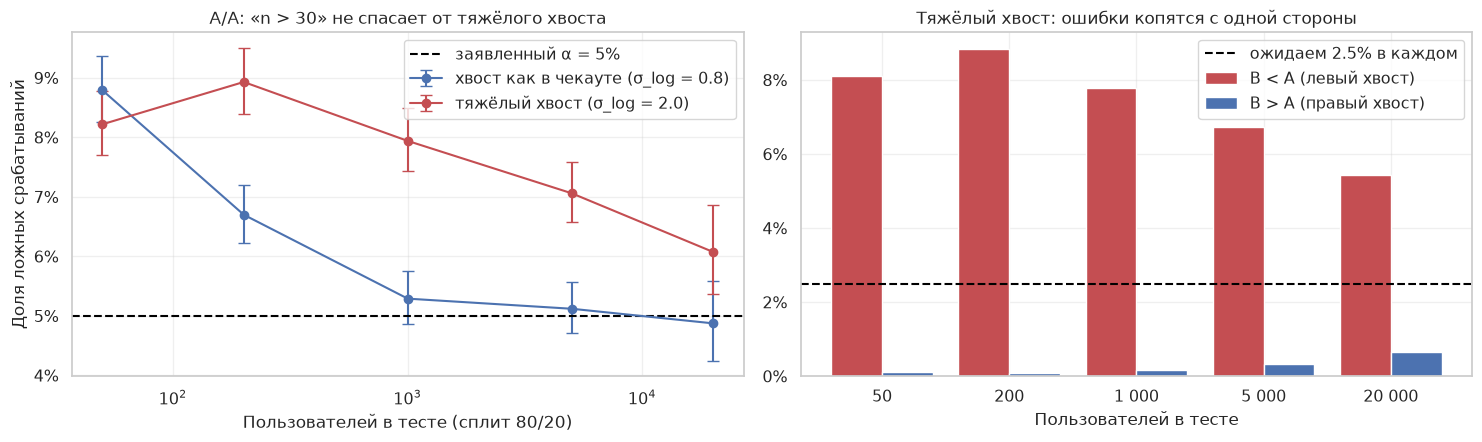

In [11]:
def revenue(rng, size, sigma):
    # Выручка пользователя: покупка с вероятностью 0.7, чек логнормальный
    return (rng.random(size) < 0.7) * rng.lognormal(7.8, sigma, size)


def aa_welch(n_total_users: int, sigma: float, n_sim: int, rng, batch: int = 2_000):
    # Доля отклонений H0 двусторонним тестом Уэлча и доля z > 0 среди них
    n_b = n_total_users // 5
    n_a = n_total_users - n_b
    z_all = []
    for _ in range(n_sim // batch):
        a, b = revenue(rng, (batch, n_a), sigma), revenue(rng, (batch, n_b), sigma)
        se = np.sqrt(a.var(axis=1, ddof=1) / n_a + b.var(axis=1, ddof=1) / n_b)
        z_all.append((b.mean(axis=1) - a.mean(axis=1)) / se)
    z = np.concatenate(z_all)
    crit = z_crit(0.05, 2)
    return np.abs(z) > crit, z < -crit, z > crit


rng = np.random.default_rng(11)
sizes = [50, 200, 1_000, 5_000, 20_000]
tails = {'хвост как в чекауте (σ_log = 0.8)': 0.8, 'тяжёлый хвост (σ_log = 2.0)': 2.0}
aa_rows, aa_rates = [], {}
for label, sigma in tails.items():
    for n in sizes:
        n_sim = 10_000 if n <= 5_000 else 4_000
        rejected, left, right = aa_welch(n, sigma, n_sim, rng, batch=min(2_000, 40_000_000 // n))
        aa_rates[(label, n)] = rejected
        aa_rows.append({'данные': label, 'N': n, 'α факт': rejected.mean(),
                        'левый хвост': left.mean(), 'правый хвост': right.mean()})
aa_table = pd.DataFrame(aa_rows).set_index(['данные', 'N'])
print(aa_table.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for (label, sigma), color in zip(tails.items(), (BLUE, RED)):
    vals = np.array([rate_with_ci(aa_rates[(label, n)]) for n in sizes])
    axes[0].errorbar(sizes, vals[:, 0], yerr=[vals[:, 0] - vals[:, 1], vals[:, 2] - vals[:, 0]],
                     fmt='o-', color=color, capsize=4, label=label)
axes[0].axhline(0.05, color='black', ls='--', label='заявленный α = 5%')
axes[0].set_xscale('log')
axes[0].set_xlabel('Пользователей в тесте (сплит 80/20)')
axes[0].set_ylabel('Доля ложных срабатываний')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[0].set_title('A/A: «n > 30» не спасает от тяжёлого хвоста')
axes[0].legend()
heavy = aa_table.loc['тяжёлый хвост (σ_log = 2.0)']
x = np.arange(len(sizes))
axes[1].bar(x - 0.2, heavy['левый хвост'], 0.4, color=RED, label='B < A (левый хвост)')
axes[1].bar(x + 0.2, heavy['правый хвост'], 0.4, color=BLUE, label='B > A (правый хвост)')
axes[1].axhline(0.025, color='black', ls='--', label='ожидаем 2.5% в каждом')
axes[1].set_xticks(x, labels=[f'{n:,}'.replace(',', ' ') for n in sizes])
axes[1].set_xlabel('Пользователей в тесте')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[1].set_title('Тяжёлый хвост: ошибки копятся с одной стороны')
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Манн–Уитни на выручке дал p = 0.001 в пользу B. Можно ли сказать финансам, что ARPU вырос?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет. U-тест проверяет не средние, а то, что случайное значение из B склонно быть больше случайного из A: P(X_B > X_A) ≠ 1/2. Значимый U возможен и при равных средних, и даже при упавшем ARPU. Пример: новый чекаут чуть поднял мелкие чеки у большинства, но отпугнул нескольких «китов». Ранги выросли, деньги упали.

Если вопрос про деньги — сравниваем средние (t-тест Уэлча, бутстреп средних), а правильность критерия на тяжёлом хвосте проверяем A/A. С бутстрепом та же ловушка: если для p-value просто объединить группы и ресэмплировать, проверяется равенство распределений, а не средних. Группы сначала сдвигают к общему среднему.

</details>

### χ² на согласие — это проверка SRM

Тот же χ², только сравниваем наблюдаемые размеры групп с заложенным сплитом. Отклонение долей (Sample Ratio Mismatch) значит, что сломано назначение или логирование, и эффектам верить нельзя.

In [12]:
for observed in ([84_700, 21_300], [84_000, 22_000]):
    total = sum(observed)
    expected = [total * (1 - SHARE_B), total * SHARE_B]
    chi2, p = stats.chisquare(observed, expected)
    a_txt, b_txt = (f'{v:,}'.replace(',', ' ') for v in observed)
    print(f'A = {a_txt}, B = {b_txt}: доля B = {observed[1] / total:.2%}, χ² = {chi2:5.1f}, p = {p:.1e}')

A = 84 700, B = 21 300: доля B = 20.09%, χ² =   0.6, p = 4.4e-01
A = 84 000, B = 22 000: доля B = 20.75%, χ² =  37.7, p = 8.1e-10


Доля B 20.75% вместо 20% выглядит мелочью, но на 106 тыс. пользователей это p ≈ 10⁻⁹. Порог SRM обычно строгий — p < 0.001, — потому что проверка идёт до всего остального. Причины SRM и что с ним делать — встреча 3.

## 6. Роли метрик и поправки

Цель бизнеса — чтобы пользователи покупали больше и дольше. Её **долгосрочная метрика** (north star) — заказы и выручка на пользователя за 28 дней и дальше. Дождаться её в тесте нельзя, поэтому у метрик теста разные роли. Классификация — по тому, **что мы с метрикой делаем** ([Dmitriev и др., 2017](https://www.microsoft.com/en-us/research/uploads/prod/2020/08/2017-08-KDDMetricInterpretationPitfalls.pdf)):

* **Метрики качества данных.** Можно ли вообще доверять эксперименту: SRM, дубли, пользователи в обеих группах, потери телеметрии (встреча 3).
* **OEC (Overall Evaluation Criterion).** Метрика, по которой решаем, запускать ли изменение. Измеряется за время теста, но должна указывать на долгосрочную ценность. Идеально — одна. В кейсе это конверсия чекаута в заказ.
* **Guardrail-метрики.** Не должны заметно ухудшиться, даже если OEC растёт: доля ошибок оплаты.
* **Локальные и диагностические метрики.** Объясняют, откуда взялось движение OEC, но решения не принимают: ARPU, время на чекауте, средний чек.

Порядок чтения результата следует из ролей: сначала данным можно верить, потом OEC, потом «ничего не сломали», и только потом «почему».

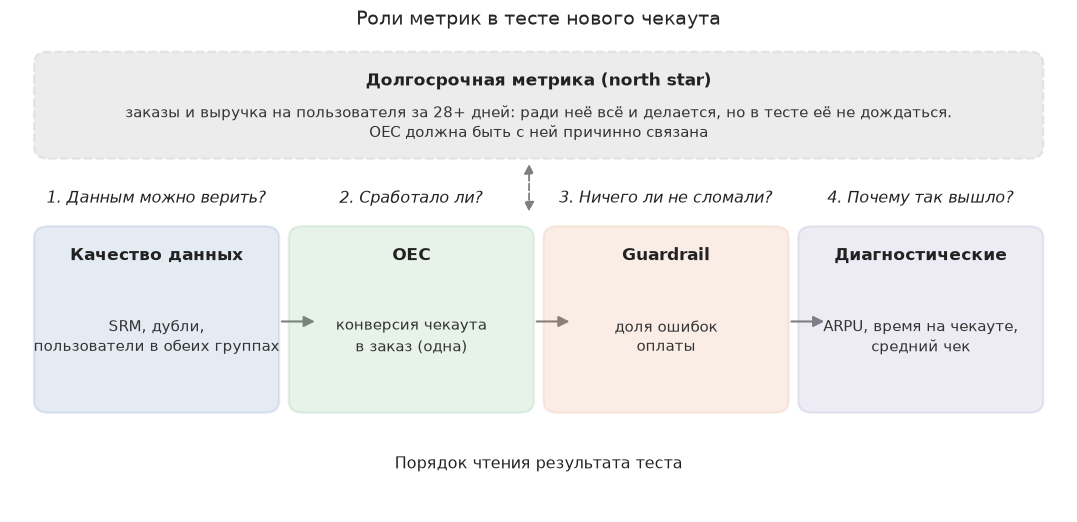

In [13]:
def draw_roles():
    fig, ax = plt.subplots(figsize=(11, 5.4))
    ax.set_xlim(0, 11)
    ax.set_ylim(0, 6)
    ax.axis('off')

    def box(x, y, w, h, title, body, color, dashed=False):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05,rounding_size=0.15', facecolor=color,
                                    edgecolor=GRAY if dashed else color, alpha=.14, linewidth=1.6,
                                    linestyle='--' if dashed else '-'))
        ax.text(x + w / 2, y + h - .32, title, ha='center', va='center', fontsize=12.5, fontweight='bold', color='#222222')
        ax.text(x + w / 2, y + h / 2 - .22, body, ha='center', va='center', fontsize=10.5, color='#333333', linespacing=1.35)

    box(.3, 4.5, 10.4, 1.25, 'Долгосрочная метрика (north star)',
        'заказы и выручка на пользователя за 28+ дней: ради неё всё и делается, но в тесте её не дождаться.\n'
        'OEC должна быть с ней причинно связана', GRAY, dashed=True)
    steps = [
        (.3, 'Данным можно верить?', 'Качество данных', 'SRM, дубли,\nпользователи в обеих группах', BLUE),
        (2.95, 'Сработало ли?', 'OEC', 'конверсия чекаута\nв заказ (одна)', GREEN),
        (5.6, 'Ничего ли не сломали?', 'Guardrail', 'доля ошибок\nоплаты', ORANGE),
        (8.25, 'Почему так вышло?', 'Диагностические', 'ARPU, время на чекауте,\nсредний чек', PURPLE),
    ]
    for k, (x, question, title, body, color) in enumerate(steps):
        ax.text(x + 1.225, 3.95, f'{k + 1}. {question}', ha='center', va='center', fontsize=11.5, color='#222222', style='italic')
        box(x, 1.3, 2.45, 2.25, title, body, color)
        if k < 3:
            ax.add_patch(FancyArrowPatch((x + 2.5, 2.4), (x + 2.9, 2.4), arrowstyle='-|>', mutation_scale=16, color=GRAY, linewidth=1.5))
    ax.add_patch(FancyArrowPatch((5.4, 3.75), (5.4, 4.42), arrowstyle='<|-|>', mutation_scale=14, color=GRAY, linewidth=1.3, linestyle='--'))
    ax.text(5.5, .55, 'Порядок чтения результата теста', ha='center', fontsize=11.5, color='#222222')
    ax.set_title('Роли метрик в тесте нового чекаута', fontsize=14, pad=8)
    plt.tight_layout()
    plt.show()


draw_roles()

### Разные метрики тестируются по-разному

Поправка на множественность следует из **правила запуска**, а не навешивается на все метрики одинаково (фреймворк Spotify, [Schultzberg и др., 2024](https://arxiv.org/abs/2402.11609); сегменты и множественность при анализе — встреча 6).

| Роль | Гипотеза | Правило запуска | Сторон | α | Мощность |
|---|---|---|---|---|---|
| Качество данных | SRM, χ² на согласие | данным можно верить | 2 | 0.001 | — |
| OEC | superiority (у нас против θ_BE) | одна метрика | 1 | из встречи 1, без поправки (при S метриках успеха — α / S) | 0.8, из встречи 1 |
| Guardrail | non-inferiority | все значимо не хуже | 1 | 0.05, без поправки | 1 − β/(G+1), G — число guardrail |
| Диагностические | superiority | «хотя бы одна» как объяснение | 2 | Холм, 0.05 на семейство (первый шаг — 0.05 / D) | не планируем |

Владелец продукта договорился с командой: решение — по конверсии, «не сломать» — ошибки оплаты, всё остальное объясняет результат. Собираем план тестов по шести метрикам.

In [14]:
ROLES = {
    'srm': 'quality',                    # доля пользователей в B против заложенных 20%
    'converted': 'oec',                  # конверсия чекаута в заказ
    'payment_error': 'guardrail',        # доля пользователей с ошибкой оплаты
    'checkout_time_sec': 'diagnostic',   # время на странице чекаута
    'revenue': 'diagnostic',             # ARPU
    'aov': 'diagnostic',                 # средний чек: Σ выручки / Σ заказов (ratio-метрика)
}


def test_plan(roles: dict, alpha_oec: float = ALPHA_OEC, alpha: float = ALPHA, power: float = POWER) -> pd.DataFrame:
    count = pd.Series(roles).value_counts()
    beta = 1 - power
    rules = {
        'quality': ('SRM, χ² на согласие', 2, 0.001, np.nan),
        'oec': ('superiority против θ_BE', 1, alpha_oec / count.get('oec', 1), power),
        # β-поправка только у guardrail: мощность OEC (power) зафиксирована встречей 1
        'guardrail': ('non-inferiority', 1, alpha, 1 - beta / (count.get('guardrail', 0) + 1)),
        # alpha диагностических — порог первого шага Холма (= Бонферрони α / D); при анализе — полный Холм
        'diagnostic': ('superiority', 2, alpha / count.get('diagnostic', 1), np.nan),
    }
    rows = {m: dict(zip(['роль', 'гипотеза', 'сторон', 'alpha', 'мощность'], (role, *rules[role])))
            for m, role in roles.items()}
    return pd.DataFrame(rows).T.astype({'сторон': int, 'alpha': float, 'мощность': float})


PLAN = test_plan(ROLES)
PLAN

,роль,гипотеза,сторон,alpha,мощность
srm,quality,"SRM, χ² на согласие",2,0.001000,NaN
converted,oec,superiority против θ_BE,1,0.500000,0.8
payment_error,guardrail,non-inferiority,1,0.050000,0.9
checkout_time_sec,diagnostic,superiority,2,0.016667,NaN
revenue,diagnostic,superiority,2,0.016667,NaN
aov,diagnostic,superiority,2,0.016667,NaN


**Вопрос.** Guardrail проверяем с α = 0.05 без поправки на число guardrail, но мощность для него поднимаем до 0.9. Почему поправка у β, а не у α? И почему для guardrail не взять α = 0.5, как у OEC?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Правило запуска — «**все** guardrail значимо не хуже».

* **Ошибка I рода.** Чтобы внедрить вредное изменение, должен ложно пройти именно тот guardrail, который реально ухудшился. Это одно сравнение с α = 0.05: условие «все» — пересечение, α не накапливается.
* **Ошибка II рода.** Хорошее изменение внедрится, только если пройдут OEC **и** все $G$ guardrail, поэтому промахи складываются: $P(\text{промах}) \le \beta_{OEC} + \sum_g \beta_g$. В схеме Spotify на мощность $1 - \beta/(G+1)$ считают все $G+1$ тестов, и общий промах не больше β.
* **У нас поправка только у guardrail:** мощность OEC 0.8 зафиксировала финмодель встречи 1. Поэтому гарантия слабее: guardrail добавляет к промаху OEC не больше 0.1, и хорошее изменение при эффекте = MDE внедрится с вероятностью не меньше 1 − 0.2 − 0.1 = 0.7. И то лишь если guardrail действительно набрал свои 0.9 — проверим ниже.

α = 0.5 у OEC оправдан финмоделью: цена ошибок в деньгах примерно симметрична около BE. У guardrail финмодели нет: рост ошибок оплаты бьёт по репутации и поддержке и не отбивается конверсией. Поэтому там классическая защита — non-inferiority с односторонним α = 0.05.

</details>

Теперь главный вопрос дизайна: **хватает ли 14 дней guardrail?** Для non-inferiority $N$ считается той же формулой: $\delta - \mu_0$ = допуск $\Delta$ (истинную разность считаем нулевой), $s$ = 1, мощность — из плана. И обратно: какую мощность guardrail получит на $N$ встречи 1.

In [15]:
p_err = base['payment_error'].mean()
NI = DESIGN['ni_payment_error']
need = pd.DataFrame({'N': {
    'converted': N_OEC,
    'payment_error': n_total(var_prop(p_err), var_prop(p_err), NI, alpha=PLAN.loc['payment_error', 'alpha'],
                             power=PLAN.loc['payment_error', 'мощность'], sides=1),
}})
need['дней'] = [duration(n)[0] for n in need['N']]
BINDING = need['N'].idxmax()

se_err = math.sqrt(var_prop(p_err) * (1 / ((1 - SHARE_B) * N_PLAN) + 1 / (SHARE_B * N_PLAN)))
GUARD_POWER = stats.norm.cdf(NI / se_err - stats.norm.ppf(1 - ALPHA))
print(f'Самая дорогая метрика: {BINDING}, {sp(need.loc[BINDING, "N"])} пользователей, {need.loc[BINDING, "дней"]} дней')
print(f'На N = {sp(N_PLAN)} ({DAYS} дней) мощность guardrail при Δ = +{100 * NI:.1f} п.п.: {GUARD_POWER:.2f}')
need

Самая дорогая метрика: payment_error, 262 029 пользователей, 35 дней
На N = 105 000 (14 дней) мощность guardrail при Δ = +0.2 п.п.: 0.58


,N,дней
converted,104126,14
payment_error,262029,35


Guardrail с допуском +0.2 п.п. хочет ≈ 262 тыс. пользователей — 35 дней. На 14 днях встречи 1 его мощность ≈ 0.58: даже если новый чекаут ничего не ломает, примерно в 4 тестах из 10 non-inferiority не докажем. Мощность всего правила (OEC и guardrail) при эффекте = MDE — ≈ 0.46 при независимых метриках, гарантированно не меньше 1 − 0.2 − 0.42 = 0.38. В ответе на вопрос о поправке на β было 0.7, но при условии, что guardrail набрал 0.9. С фактическими 0.58 гарантия падает до 0.38.

**Вопрос.** Guardrail недобирает мощность: 0.58 вместо 0.9. Назовите три варианта, что с этим делать, и выберите один для кейса.

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

(а) **Продлить тест до 5 недель.** Ломает экономику встречи 1: каждая неделя теста стоит денег.

(б) **Ослабить допуск** до ≈ +0.32 п.п. (≈ 16% от базы) — при нём 14 дней дают мощность 0.9. Нужно согласие владельца продукта и поддержки.

(в) **Оставить 14 дней и допуск +0.2 п.п. и записать в док правило эскалации.** Решает верхняя граница ДИ, а не точечная оценка: если она ≥ +0.2 п.п. — «не внедряем как есть», даже когда оценка меньше +0.2 п.п. Внедрение приостановлено, причину разбираем, после исправления — подтверждающий тест 50/50 на мощность guardrail 0.9: ≈ 168 тыс. пользователей, 23 дня трафика → 4 недели. Автоотката нет: если OEC выше θ_BE, вариант чиним, а не выбрасываем.

Для кейса берём (в): допуск и α фиксируем, недобор мощности и правило эскалации — в доке. Главное — решить **до** старта. «Но оценка же меньше +0.2» после результата — это уже подгонка.

</details>

In [16]:
NI_FOR_PLAN = (stats.norm.ppf(1 - ALPHA) + stats.norm.ppf(PLAN.loc['payment_error', 'мощность'])) * se_err

# Если guardrail не пройдёт — подтверждающий тест: 50/50, та же граница, мощность guardrail из плана
N_CONFIRM = n_total(var_prop(p_err), var_prop(p_err), NI, share_b=0.5, alpha=PLAN.loc['payment_error', 'alpha'],
                    power=PLAN.loc['payment_error', 'мощность'], sides=1)
CONFIRM_DAYS, CONFIRM_WEEKS = duration(N_CONFIRM)
print(f'Мощность {PLAN.loc["payment_error", "мощность"]:.1f} на {DAYS} днях дал бы Δ = +{100 * NI_FOR_PLAN:.2f} п.п.')
print(f'Подтверждающий тест 50/50 на мощность {PLAN.loc["payment_error", "мощность"]:.1f}: '
      f'N = {sp(N_CONFIRM)}, {CONFIRM_DAYS} дн. трафика → {CONFIRM_WEEKS} нед.')

Мощность 0.9 на 14 днях дал бы Δ = +0.32 п.п.
Подтверждающий тест 50/50 на мощность 0.9: N = 167 699, 23 дн. трафика → 4 нед.


## 7. Ускорение: меньше дисперсия — короче тест

В формуле из раздела 3 $N$ пропорционален $\sigma^2$. Снизили дисперсию на 30% — тест короче на 30% при тех же α, мощности и MDE. Четыре рабочих инструмента:

| Метод | Что делает | Что нужно |
|---|---|---|
| Стратификация | убирает дисперсию между сегментами | сегменты, известные до теста |
| CUPED | вычитает часть метрики, объяснимую ковариатой | ковариата, не зависящая от воздействия (обычно предпериод) |
| Линеаризация | **сама не снижает дисперсию**: делает метрику отношения пользовательской | числитель и знаменатель по пользователям |
| Работа с выбросами | ограничивает влияние экстремальных значений | порог, не зависящий от воздействия |

Что ещё бывает: VWE (веса по шумности пользователя), CUPAC и MLRATE (ковариата из ML-модели), бакетизация (ускоряет расчёты, а не тест).

### [Стратификация](https://habr.com/ru/companies/X5Tech/articles/596279/)

Дисперсия раскладывается на «внутри страт» и «между стратами»:

$$
\sigma^2 = \sum_k w_k \sigma_k^2 + \sum_k w_k (\mu_k - \mu)^2
$$

Стратификация убирает второе слагаемое. Сравним четыре схемы на двух равных стратах со средними 2000 и 3000: случайные группы; **стратифицированное сэмплирование** (доли страт в группах фиксированы) с обычным средним и со **стратифицированным средним** $\bar Y_{strat} = \sum_k w_k \bar Y_k$; **постстратификация** (группы случайные, среднее стратифицированное).

**Вопрос.** Группы собрали стратифицированно: в каждой ровно половина пользователей из каждой страты. А сравниваем обычным t-тестом по средним. Что станет с ошибкой I рода и мощностью?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Оценка эффекта станет точнее: разброс между стратами больше не попадает в разность групп. Но t-тест этого не знает и считает SE как для случайных групп, с полной дисперсией. SE завышена, тест консервативен: в симуляции ниже α ≈ 1% вместо 5%, а мощность почти не выросла (0.85 против 0.79).

Выигрыш потерян впустую. Его возвращает **стратифицированное среднее** и SE по дисперсиям внутри страт: α снова ≈ 5%, мощность ≈ 0.95. Правило: способ формирования групп и способ оценки должны быть согласованы.

</details>

Дисперсия: 640,625 = 390,625 (внутри страт) + 250,000 (между стратами)
Расчётный объём выборки на группу: 1006



                                       Ошибка I рода  Мощность  SD оценки  Средняя SE
Случайно, обычное среднее                      0.048     0.791     35.674      35.674
Страт. сэмплирование, обычное среднее          0.012     0.854     27.518      35.685
Страт. сэмплирование, страт. среднее           0.054     0.952     28.241      27.878
Постстратификация                              0.052     0.946     28.013      27.862


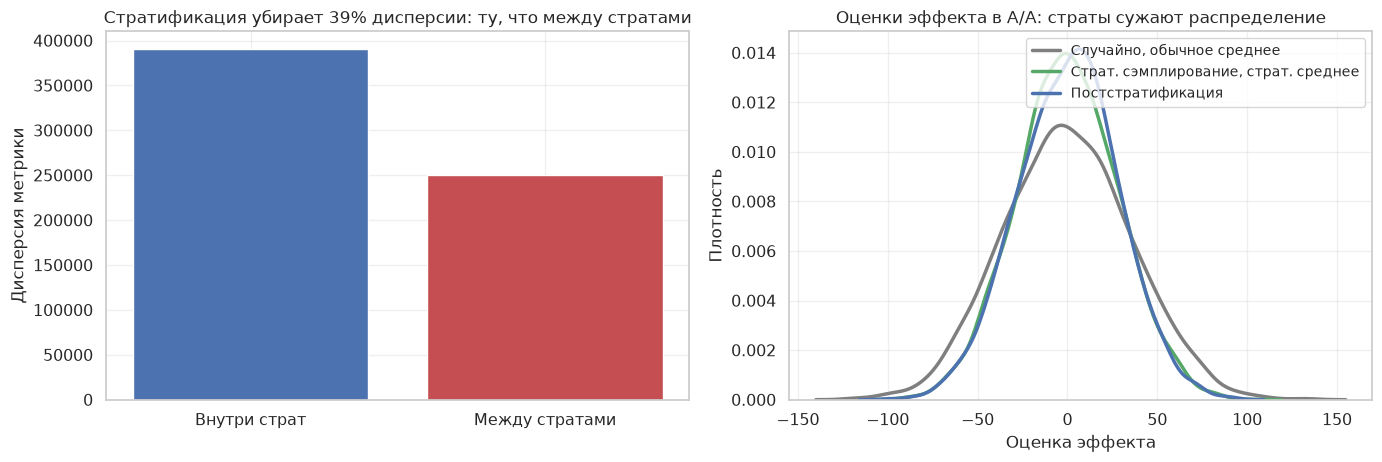

In [17]:
STRAT_CONFIG = {
    "alpha": 0.05,
    "beta": 0.2,
    "effect": 100.0,
    "weights": (0.5, 0.5),  # доли страт в популяции
    "means": (2_000.0, 3_000.0),
    "stds": (625.0, 625.0),
}
strat_weights = np.array(STRAT_CONFIG["weights"])
strat_means = np.array(STRAT_CONFIG["means"])
strat_stds = np.array(STRAT_CONFIG["stds"])

# Общая дисперсия метрики: среднее дисперсий внутри страт + разброс средних между стратами
overall_mean = strat_weights @ strat_means
var_within = strat_weights @ strat_stds ** 2
var_between = strat_weights @ (strat_means - overall_mean) ** 2
var_total = var_within + var_between

z_sum = stats.norm.ppf(1 - STRAT_CONFIG["alpha"] / 2) + stats.norm.ppf(1 - STRAT_CONFIG["beta"])
strat_sample_size = int(np.ceil(2 * z_sum ** 2 * var_total / STRAT_CONFIG["effect"] ** 2))
print(f'Дисперсия: {var_total:,.0f} = {var_within:,.0f} (внутри страт) + {var_between:,.0f} (между стратами)')
print(f'Расчётный объём выборки на группу: {strat_sample_size}\n')


def generate_group(rng: np.random.Generator, size: tuple[int, int], stratified: bool, effect: float = 0.0) -> tuple[np.ndarray, np.ndarray]:
    """Генерирует метрику и принадлежность к первой страте для группы с фиксированными или случайными долями страт."""
    if stratified:
        in_first = np.broadcast_to(np.arange(size[1]) < round(size[1] * strat_weights[0]), size)
    else:
        in_first = rng.random(size) < strat_weights[0]
    means = np.where(in_first, strat_means[0], strat_means[1])
    stds = np.where(in_first, strat_stds[0], strat_stds[1])
    return rng.normal(means + effect, stds), in_first


def plain_estimate(y: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Возвращает обычное среднее и выборочную дисперсию метрики."""
    return y.mean(axis=1), y.var(axis=1, ddof=1)


def strat_estimate(y: np.ndarray, in_first: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Возвращает стратифицированное среднее и взвешенную дисперсию внутри страт."""
    mean_one, var_one, _ = masked_mean_var(y, in_first)
    mean_two, var_two, _ = masked_mean_var(y, ~in_first)
    return (strat_weights[0] * mean_one + strat_weights[1] * mean_two,
            strat_weights[0] * var_one + strat_weights[1] * var_two)


def simulate_strat(n: int, n_simulations: int = 4_000, batch: int = 500) -> dict[str, dict[str, np.ndarray]]:
    """Сравнивает способы формирования групп и оценки среднего на A/A и A/B."""
    rng = np.random.default_rng(42)
    # Название: (стратифицированное сэмплирование, стратифицированное среднее)
    schemes = {
        'Случайно, обычное среднее': (False, False),
        'Страт. сэмплирование, обычное среднее': (True, False),
        'Страт. сэмплирование, страт. среднее': (True, True),
        'Постстратификация': (False, True),
    }
    result = {name: {'aa': [], 'ab': [], 'delta': [], 'se': []} for name in schemes}
    for _ in range(n_simulations // batch):
        for key, effect in (('aa', 0.0), ('ab', STRAT_CONFIG['effect'])):
            for name, (stratified, use_strat_mean) in schemes.items():
                y_c, first_c = generate_group(rng, (batch, n), stratified)
                y_t, first_t = generate_group(rng, (batch, n), stratified, effect)
                mean_c, var_c = strat_estimate(y_c, first_c) if use_strat_mean else plain_estimate(y_c)
                mean_t, var_t = strat_estimate(y_t, first_t) if use_strat_mean else plain_estimate(y_t)
                delta, se = mean_t - mean_c, np.sqrt((var_c + var_t) / n)
                result[name][key].append(z_pvalue(delta, se) < STRAT_CONFIG['alpha'])
                if key == 'aa':
                    result[name]['delta'].append(delta)
                    result[name]['se'].append(se)
    return {name: {key: np.concatenate(values) for key, values in row.items()} for name, row in result.items()}


strat_results = simulate_strat(strat_sample_size)
print(pd.DataFrame({
    name: {
        'Ошибка I рода': row['aa'].mean(),
        'Мощность': row['ab'].mean(),
        'SD оценки': row['delta'].std(),
        'Средняя SE': row['se'].mean(),
    } for name, row in strat_results.items()
}).T.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].bar(['Внутри страт', 'Между стратами'], [var_within, var_between], color=[BLUE, RED])
axes[0].set_title(f'Стратификация убирает {var_between / var_total:.0%} дисперсии: ту, что между стратами')
axes[0].set_ylabel('Дисперсия метрики')
styles = {'Случайно, обычное среднее': GRAY, 'Страт. сэмплирование, страт. среднее': GREEN, 'Постстратификация': BLUE}
for name, color in styles.items():
    sns.kdeplot(strat_results[name]['delta'], ax=axes[1], label=name, color=color, linewidth=2.5)
axes[1].set_title('Оценки эффекта в A/A: страты сужают распределение')
axes[1].set_xlabel('Оценка эффекта')
axes[1].set_ylabel('Плотность')
axes[1].legend(loc='upper right', fontsize=10)
plt.tight_layout()
plt.show()

* **Стратифицированное сэмплирование без стратифицированного среднего** сломано: оценка стала точнее (SD ≈ 27.5), но тест считает SE как для случайных групп (≈ 35.7). Ошибка I рода ≈ 1% вместо 5%.
* **Стратифицированное среднее** возвращает α к 5% и поднимает мощность с ≈ 0.79 до ≈ 0.95.
* **Постстратификация** почти не уступает: плата за случайный состав групп — порядка $1/n^2$, выигрыш — порядка $1/n$. Страты определяем **до** теста, а воздействие не должно переводить пользователя из страты в страту.

### [CUPED](https://habr.com/ru/companies/X5Tech/articles/780270/)

CUPED ([Deng et al., 2013](https://doi.org/10.1145/2433396.2433413)) заменяет метрику $Y$ на

$$
Y_{cuped} = Y - \theta (X - \bar X)
$$

$$
\theta = \frac{\mathrm{cov}(Y, X)}{\mathrm{Var}(X)}
$$

где $X$ — ковариата до теста (чаще всего та же метрика на предпериоде), а $\theta$ и $\bar X$ считаются по **объединённым** данным обеих групп. В обеих группах в среднем вычитается одно и то же, поэтому эффект не смещается, а дисперсия падает до $\mathrm{Var}(Y) (1 - \rho^2)$. Выборка сокращается в $1/(1-\rho^2)$ раз.

Почему θ общий: с ним в обеих группах вычитается одна и та же функция от $X$, а среднее $X$ в группах одинаково по рандомизации. Свой θ в группе B оценивался бы на данных, где уже есть эффект, и «подстраивался» бы под него; на малых группах это даёт смещение.

Проверим на 2 000 симуляциях с истинным эффектом 20 для двух ковариат: слабой (ρ = 0.3) и сильной (ρ = 0.7). Заодно сравним CUPED с регрессией $Y = a + \tau T + \theta X + \varepsilon$ (ANCOVA).

Истинный эффект: 20
ρ                            0.3     0.7
Var CUPED / Var Y          0.909   0.510
1 − ρ²                     0.910   0.510
оценка без CUPED          19.618  19.555
оценка CUPED              19.686  19.679
оценка OLS                19.696  19.689
SE Монте-Карло для CUPED   0.284   0.209
SD без CUPED              13.530  13.244
SD CUPED                  12.717   9.360
α CUPED                    0.052   0.038
мощность без CUPED         0.304   0.302
мощность CUPED             0.332   0.530

Один прогон (ρ = 0.7): CUPED 32.5, OLS 32.5, SE 9.6


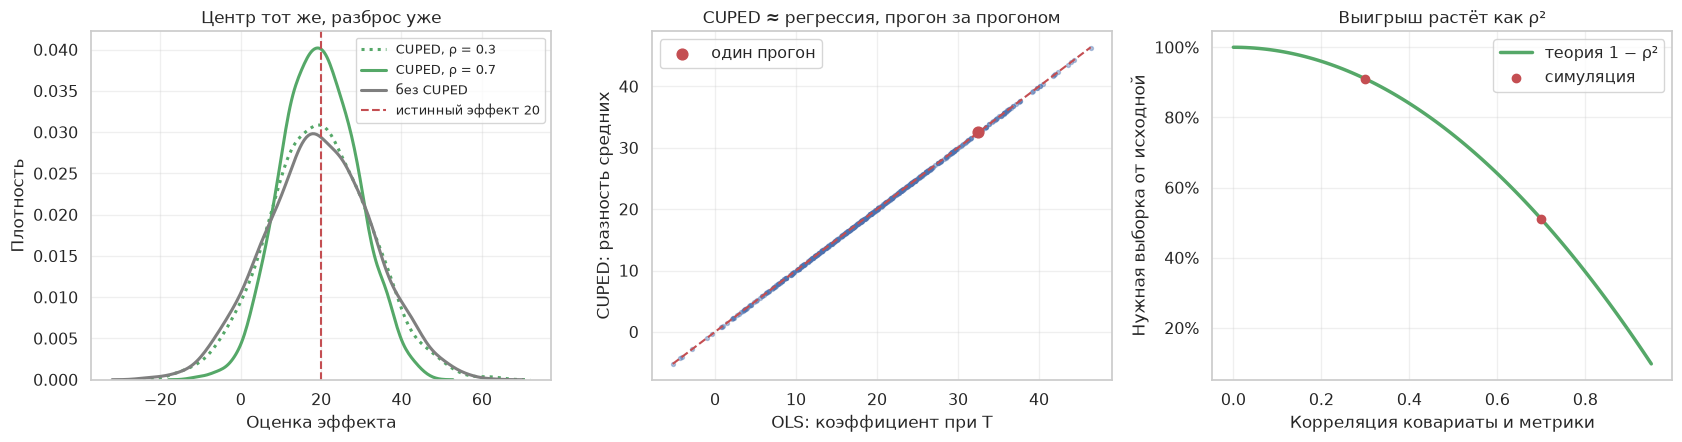

In [18]:
CUPED_CONFIG = {'n_simulations': 2_000, 'sample_size': 1_000, 'effect': 20.0, 'mean': 2_000.0, 'sigma': 300.0}


def generate_metric_covariate(rng, size, corr, mean=2_000.0, sigma=300.0):
    # Метрика и ковариата с заданной корреляцией
    covariate = rng.normal(0, 1, size)
    metric = corr * covariate + np.sqrt(1 - corr ** 2) * rng.normal(0, 1, size)
    return mean + sigma * metric, mean + sigma * covariate


def cuped_pair(y_c, x_c, y_t, x_t):
    # CUPED-метрика обеих групп с общим θ и общим средним ковариаты (по строкам)
    x, y = np.hstack([x_c, x_t]), np.hstack([y_c, y_t])
    xc = x - x.mean(axis=1, keepdims=True)
    theta = (xc * (y - y.mean(axis=1, keepdims=True))).sum(axis=1, keepdims=True) / (xc ** 2).sum(axis=1, keepdims=True)
    x_mean = x.mean(axis=1, keepdims=True)
    return y_c - theta * (x_c - x_mean), y_t - theta * (x_t - x_mean)


def ols_effect(y_c, x_c, y_t, x_t):
    # Коэффициент при T в регрессии Y ~ 1 + T + X (наклон по X общий для групп)
    def centered(a):
        return a - a.mean(axis=1, keepdims=True)
    slope = ((centered(x_c) * centered(y_c)).sum(axis=1) + (centered(x_t) * centered(y_t)).sum(axis=1)) / \
            ((centered(x_c) ** 2).sum(axis=1) + (centered(x_t) ** 2).sum(axis=1))
    return (y_t.mean(axis=1) - y_c.mean(axis=1)) - slope * (x_t.mean(axis=1) - x_c.mean(axis=1))


def diff_se(a, b):
    return b.mean(axis=1) - a.mean(axis=1), np.sqrt(a.var(axis=1, ddof=1) / a.shape[1] + b.var(axis=1, ddof=1) / b.shape[1])


size = (CUPED_CONFIG['n_simulations'], CUPED_CONFIG['sample_size'])
cuped_rows, cuped_est = [], {}
for rho, seed in ((0.3, 1), (0.7, 2)):
    rng = np.random.default_rng(seed)
    y_c, x_c = generate_metric_covariate(rng, size, rho)
    y_t, x_t = generate_metric_covariate(rng, size, rho)
    y_e = y_t + CUPED_CONFIG['effect']
    out = {}
    for key, y_test in (('aa', y_t), ('ab', y_e)):
        c_c, c_t = cuped_pair(y_c, x_c, y_test, x_t)
        out[key] = {'Без CUPED': diff_se(y_c, y_test), 'CUPED': diff_se(c_c, c_t)}
    ols = ols_effect(y_c, x_c, y_e, x_t)
    cuped_est[rho] = {'naive': out['ab']['Без CUPED'][0], 'cuped': out['ab']['CUPED'][0], 'ols': ols,
                      'se_cuped': out['ab']['CUPED'][1]}
    c_c, _ = cuped_pair(y_c, x_c, y_e, x_t)
    cuped_rows.append({
        'ρ': rho,
        'Var CUPED / Var Y': c_c.var(axis=1).mean() / y_c.var(axis=1).mean(),
        '1 − ρ²': 1 - rho ** 2,
        'оценка без CUPED': out['ab']['Без CUPED'][0].mean(),
        'оценка CUPED': out['ab']['CUPED'][0].mean(),
        'оценка OLS': ols.mean(),
        'SE Монте-Карло для CUPED': out['ab']['CUPED'][0].std() / np.sqrt(size[0]),
        'SD без CUPED': out['ab']['Без CUPED'][0].std(),
        'SD CUPED': out['ab']['CUPED'][0].std(),
        'α CUPED': np.mean(z_pvalue(*out['aa']['CUPED']) < 0.05),
        'мощность без CUPED': np.mean(z_pvalue(*out['ab']['Без CUPED']) < 0.05),
        'мощность CUPED': np.mean(z_pvalue(*out['ab']['CUPED']) < 0.05),
    })
cuped_sim = pd.DataFrame(cuped_rows).set_index('ρ')
print(f"Истинный эффект: {CUPED_CONFIG['effect']:.0f}")
print(cuped_sim.round(3).T.to_string())
one = cuped_est[0.7]
print(f"\nОдин прогон (ρ = 0.7): CUPED {one['cuped'][0]:.1f}, OLS {one['ols'][0]:.1f}, SE {one['se_cuped'][0]:.1f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for rho, style in ((0.3, ':'), (0.7, '-')):
    sns.kdeplot(cuped_est[rho]['cuped'], ax=axes[0], color=GREEN, linestyle=style, linewidth=2.2, label=f'CUPED, ρ = {rho}')
sns.kdeplot(cuped_est[0.7]['naive'], ax=axes[0], color=GRAY, linewidth=2.2, label='без CUPED')
axes[0].axvline(CUPED_CONFIG['effect'], color=RED, ls='--', label='истинный эффект 20')
axes[0].set_xlabel('Оценка эффекта')
axes[0].set_ylabel('Плотность')
axes[0].set_title('Центр тот же, разброс уже')
axes[0].legend(fontsize=9)
axes[1].scatter(cuped_est[0.7]['ols'][:500], cuped_est[0.7]['cuped'][:500], s=8, alpha=0.4, color=BLUE)
axes[1].scatter(cuped_est[0.7]['ols'][:1], cuped_est[0.7]['cuped'][:1], s=60, color=RED, label='один прогон')
lims = [cuped_est[0.7]['ols'][:500].min(), cuped_est[0.7]['ols'][:500].max()]
axes[1].plot(lims, lims, color=RED, ls='--')
axes[1].set_xlabel('OLS: коэффициент при T')
axes[1].set_ylabel('CUPED: разность средних')
axes[1].set_title('CUPED ≈ регрессия, прогон за прогоном')
axes[1].legend()
rhos = np.linspace(0, 0.95, 100)
axes[2].plot(rhos, 1 - rhos ** 2, color=GREEN, linewidth=2.5, label='теория 1 − ρ²')
axes[2].scatter(cuped_sim.index, cuped_sim['Var CUPED / Var Y'], color=RED, zorder=3, label='симуляция')
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[2].set_xlabel('Корреляция ковариаты и метрики')
axes[2].set_ylabel('Нужная выборка от исходной')
axes[2].set_title('Выигрыш растёт как ρ²')
axes[2].legend()
plt.tight_layout()
plt.show()

* **Несмещённость.** Средняя оценка по 2 000 прогонам ≈ 20 и без CUPED, и с ним, и в регрессии: отличие от 20 в пределах двух SE Монте-Карло (≈ 0.2–0.3). В отдельном прогоне оценка легко уходит от 20 на две SE (≈ ±19 при ρ = 0.7) — это шум, а не смещение. CUPED и OLS почти совпадают: точки лежат на диагонали.
* **Дисперсия** падает до $1 - \rho^2$: при ρ = 0.3 это −9% (почти ничего), при ρ = 0.7 — −49%. При той же выборке мощность растёт с ≈ 0.30 до ≈ 0.53; чтобы без CUPED получить столько же, нужна вдвое большая выборка.
* **A/A** с CUPED даёт α ≈ 4–5%: на 2 000 прогонах шум самой доли — около ±1 п.п.
* Регрессия обобщает CUPED: несколько ковариат — это просто регрессия с несколькими признаками.

**Вопрос.** θ можно взять «на глаз», не оптимальный. Может ли CUPED тогда увеличить дисперсию? И можно ли ковариатой взять выручку за первые дни теста?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

**Может.** Дисперсия скорректированной метрики — $\mathrm{Var}(Y) - 2\theta \mathrm{cov}(Y, X) + \theta^2 \mathrm{Var}(X)$. Это парабола по θ с минимумом в оптимальном θ*. Она ниже исходной дисперсии только при θ между 0 и 2θ*; дальше CUPED шумит сильнее, чем исходная метрика. Смещения при этом нет: θ общий, и эффект он не трогает. Портится только мощность.

**Ковариата за первые дни теста — нельзя.** Выручка во время теста уже зависит от воздействия, и CUPED вычтет часть эффекта. Ковариата — только то, что измерено **до** старта. Новым пользователям без предпериода её заполняют одним правилом в обеих группах (нулём или средним): оценка остаётся несмещённой, просто на них нет выигрыша. Правило фиксируем в дизайн-доке.

</details>

#### CUPED на выручке кейса

Финансы спрашивают: «А если решать по деньгам — ARPU?» Решение остаётся за конверсией (раздел 6), но вопрос честный: на сколько CUPED сократил бы тест по ARPU и годится ли он, чтобы сузить ДИ ARPU при анализе (встреча 6). Ковариаты из предпериода — `revenue_prev28` и `orders_prev28`: от группы они не зависят.

In [19]:
def cuped(y: np.ndarray, x: np.ndarray) -> tuple[np.ndarray, float]:
    # CUPED-метрика и θ; θ и среднее X — по всем переданным данным
    y, x = np.asarray(y, float), np.asarray(x, float)
    theta = np.cov(y, x)[0, 1] / np.var(x, ddof=1)
    return y - theta * (x - x.mean()), float(theta)


rows = []
for metric in ('revenue', 'converted'):
    for cov in ('revenue_prev28', 'orders_prev28'):
        y_m, x_m = base[metric].to_numpy(), base[cov].to_numpy()
        adjusted, theta = cuped(y_m, x_m)
        rows.append({'метрика': metric, 'ковариата': cov, 'θ': theta, 'ρ': np.corrcoef(y_m, x_m)[0, 1],
                     'снижение дисперсии': 1 - adjusted.var() / y_m.var()})
cuped_case = pd.DataFrame(rows).set_index(['метрика', 'ковариата'])

y_rev, x_prev = base['revenue'].to_numpy(), base['revenue_prev28'].to_numpy()
Y_CUPED, THETA = cuped(y_rev, x_prev)
VAR_CUT = 1 - Y_CUPED.var() / y_rev.var()
cuped_case.style.format({'θ': '{:.3g}', 'ρ': '{:.3f}', 'снижение дисперсии': '{:.1%}'})

Лучшая ковариата для выручки — выручка до теста: дисперсия ниже на ≈ 37%. Число заказов до теста даёт меньше, а для конверсии обе ковариаты почти бесполезны (ρ ≈ 0.1–0.13, выигрыш 1–2%). CUPED работает для той метрики, чьё прошлое на неё похоже.

Теперь в днях: сколько нужно на ARPU с MDE = +2% без CUPED и с ним? Дисперсия падает на `VAR_CUT` — на ту же долю падает $N$.

In [20]:
ARPU = y_rev.mean()
MDE_ARPU = DESIGN['mde_arpu_rel'] * ARPU
N_ARPU = n_total(y_rev.var(ddof=1), y_rev.var(ddof=1), MDE_ARPU)
N_ARPU_CUPED = n_total(Y_CUPED.var(ddof=1), Y_CUPED.var(ddof=1), MDE_ARPU)
(days_raw, weeks_raw), (days_cuped, weeks_cuped) = duration(N_ARPU), duration(N_ARPU_CUPED)
DAYS_SAVED = days_raw - days_cuped
print(f'ARPU = {sp(ARPU)} ₽, MDE = +{sp(MDE_ARPU)} ₽ (+{DESIGN["mde_arpu_rel"]:.0%})')
print(f'Без CUPED: N = {sp(N_ARPU)}, {days_raw} дней → {weeks_raw} нед.')
print(f'С CUPED:   N = {sp(N_ARPU_CUPED)}, {days_cuped} дней → {weeks_cuped} нед.')
print(f'Сэкономили {DAYS_SAVED} дней трафика ({1 - N_ARPU_CUPED / N_ARPU:.0%})')

ARPU = 2 604 ₽, MDE = +52 ₽ (+2%)
Без CUPED: N = 204 304, 28 дней → 4 нед.
С CUPED:   N = 127 873, 18 дней → 3 нед.
Сэкономили 10 дней трафика (37%)


**Проверка несмещённости на своих данных.** Делим контроль случайно 80/20 две тысячи раз. В «A/A» эффекта нет; в «A/B» на **том же** делении добавляем псевдо-группе B ровно `MDE_ARPU` рублей. Для каждого деления считаем разность средних без CUPED и с CUPED (θ пересчитываем по объединённым данным) и p-value.

Средняя оценка по 2 000 делениям — плохой судья: выручка с тяжёлым хвостом, SD оценки ≈ 29 ₽ (с CUPED ≈ 23 ₽), и среднее гуляет на 1–2 ₽ даже без CUPED, где смещения нет по построению. Поэтому смотрим **разность A/B − A/A на одном и том же делении**: шум выручки в ней сокращается, и остаётся только то, что метод сделал с подмешанным эффектом.

In [21]:
R_CUPED = 2_000
res = {key: np.empty(R_CUPED) for key in ('raw_aa', 'cup_aa', 'raw_ab', 'cup_ab',
                                          'p_raw_aa', 'p_cup_aa', 'p_raw_ab', 'p_cup_ab')}


def diff_p(values, is_b):
    a, b = values[~is_b], values[is_b]
    d = b.mean() - a.mean()
    return d, 2 * stats.norm.sf(abs(d) / np.sqrt(a.var(ddof=1) / a.size + b.var(ddof=1) / b.size))


for r in range(R_CUPED):
    is_b = rng_case.random(y_rev.size) < SHARE_B
    for key, shift in (('aa', 0.0), ('ab', MDE_ARPU)):
        y_r = y_rev + shift * is_b
        res[f'raw_{key}'][r], res[f'p_raw_{key}'][r] = diff_p(y_r, is_b)
        res[f'cup_{key}'][r], res[f'p_cup_{key}'][r] = diff_p(cuped(y_r, x_prev)[0], is_b)

SHIFT = {'raw': res['raw_ab'] - res['raw_aa'], 'cup': res['cup_ab'] - res['cup_aa']}  # одно и то же деление
summary = pd.DataFrame({
    'средняя оценка A/A': [res['raw_aa'].mean(), res['cup_aa'].mean()],
    '±2 SE Монте-Карло': [2 * res[k].std() / np.sqrt(R_CUPED) for k in ('raw_aa', 'cup_aa')],
    'A/B − A/A, среднее': [SHIFT['raw'].mean(), SHIFT['cup'].mean()],
    'A/B − A/A, макс. отклонение от MDE': [np.abs(SHIFT[k] - MDE_ARPU).max() for k in ('raw', 'cup')],
    'SD оценки': [res['raw_ab'].std(), res['cup_ab'].std()],
    'α (A/A)': [(res['p_raw_aa'] < ALPHA).mean(), (res['p_cup_aa'] < ALPHA).mean()],
    'мощность на этих N': [(res['p_raw_ab'] < ALPHA).mean(), (res['p_cup_ab'] < ALPHA).mean()],
}, index=['без CUPED', 'CUPED'])
print(f'Подмешанный эффект: {MDE_ARPU:.3f} ₽; макс. отклонение сдвига на делении с CUPED: '
      f"{np.abs(SHIFT['cup'] - MDE_ARPU).max():.4f} ₽")
summary.round(4)

Подмешанный эффект: 52.088 ₽; макс. отклонение сдвига на делении с CUPED: 0.0071 ₽


,средняя оценка A/A,±2 SE Монте-Карло,"A/B − A/A, среднее","A/B − A/A, макс. отклонение от MDE",SD оценки,α (A/A),мощность на этих N
без CUPED,1.6636,1.3113,52.0884,0.0000,29.3226,0.052,0.458
CUPED,1.4429,1.0200,52.0878,0.0071,22.8085,0.042,0.643


Подмешанные 52 ₽ проходят через CUPED без потерь: на каждом делении сдвиг отличается от подмешанного на тысячные доли рубля. A/A с CUPED держит α около 5%, SD оценки падает с ≈ 29 до ≈ 23 ₽, мощность на этих $N$ растёт с ≈ 0.46 до ≈ 0.64.

**Итог:** если бы OEC были деньги, CUPED по `revenue_prev28` срезал бы дисперсию на ≈ 37% и сэкономил неделю. Для нашей OEC (конверсии) выигрыш ≈ 1%, поэтому длительность остаётся за встречей 1, а CUPED применим к ARPU при анализе, чтобы сузить его ДИ.

### [Линеаризация](https://doi.org/10.1145/3159652.3159699)

Метрика отношения (CTR, средний чек) — это отношение сумм, её наблюдения — показы или заказы, а не пользователи. Единица анализа не совпадает с единицей рандомизации (раздел 1), и наивный тест врёт. Дисперсию отношения считает дельта-метод. Линеаризация ([Budylin et al., 2018](https://doi.org/10.1145/3159652.3159699)) делает то же проще: превращает отношение в пользовательскую метрику

$$
Lin(u) = Y(u) - R_{ctrl} X(u)
$$

где $R_{ctrl}$ — отношение в контроле. Дальше работает любой метод для пользовательских метрик — t-тест, CUPED, стратификация. Проверим на CTR с ростом на 5%.

                              Ошибка I рода  Мощность
По показам, клики независимы          0.191     0.586
Среднее CTR пользователей             0.048     0.260
Дельта-метод                          0.052     0.340
Линеаризация                          0.052     0.346
Линеаризация с весами                 0.046     0.384
Линеаризация + CUPED                  0.048     0.462


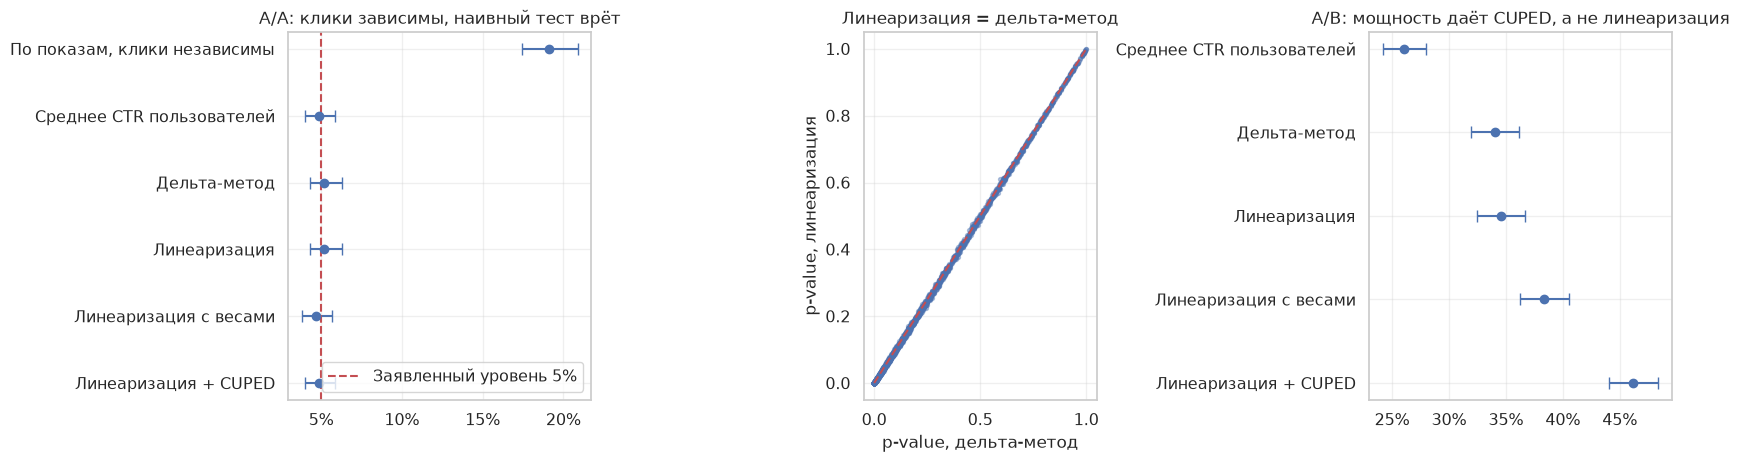

In [22]:
LIN_CONFIG = {
    "n_simulations": 2_000,
    "n_users": 3_000,
    "uplift": 0.05,  # рост CTR на 5%
}


def generate_ctr_data(rng: np.random.Generator, size: tuple[int, int], uplift: float = 0.0) -> dict[str, np.ndarray]:
    """Генерирует просмотры и клики пользователей до и во время эксперимента."""
    activity = rng.gamma(1.0, 12.0, size)  # у пользователей разная активность
    ctr = rng.beta(2, 18, size) * np.clip(1.6 - 0.03 * activity, 0.4, 1.6)  # и разная склонность кликать
    views_pre = 1 + rng.poisson(activity)
    views = 1 + rng.poisson(activity)
    return {
        'views_pre': views_pre,
        'clicks_pre': rng.binomial(views_pre, ctr),
        'views': views,
        'clicks': rng.binomial(views, np.minimum(ctr * (1 + uplift), 1)),
    }


def ratio_delta_var(views: np.ndarray, clicks: np.ndarray) -> np.ndarray:
    """Считает дисперсию ratio-метрики дельта-методом по пользовательским суммам."""
    n = views.shape[1]
    mean_x, mean_y = views.mean(axis=1, keepdims=True), clicks.mean(axis=1, keepdims=True)
    ratio = mean_y / mean_x
    return ((clicks - ratio * views) ** 2).sum(axis=1) / (n - 1) / (n * mean_x[:, 0] ** 2)


def ratio_tests(control: dict[str, np.ndarray], pilot: dict[str, np.ndarray]) -> dict[str, np.ndarray]:
    """Возвращает p-value разных критериев для метрики отношения."""
    x_c, y_c, x_t, y_t = control['views'], control['clicks'], pilot['views'], pilot['clicks']
    r_c = y_c.sum(axis=1, keepdims=True) / x_c.sum(axis=1, keepdims=True)
    r_t = y_t.sum(axis=1, keepdims=True) / x_t.sum(axis=1, keepdims=True)
    delta = (r_t - r_c)[:, 0]

    # Клики как независимые испытания: типичная ошибка
    se_naive = np.sqrt(r_c[:, 0] * (1 - r_c[:, 0]) / x_c.sum(axis=1) + r_t[:, 0] * (1 - r_t[:, 0]) / x_t.sum(axis=1))
    se_delta = np.sqrt(ratio_delta_var(x_c, y_c) + ratio_delta_var(x_t, y_t))

    lin_c, lin_t = y_c - r_c * x_c, y_t - r_c * x_t

    w_c, w_t = np.sqrt(x_c), np.sqrt(x_t)
    r_rew = ((w_c * y_c / x_c).sum(axis=1) / w_c.sum(axis=1))[:, None]
    rew_c, rew_t = (y_c - r_rew * x_c) / w_c, (y_t - r_rew * x_t) / w_t

    # CUPED поверх линеаризации: ковариата — та же линеаризованная метрика на предпериоде
    r_pre = control['clicks_pre'].sum(axis=1, keepdims=True) / control['views_pre'].sum(axis=1, keepdims=True)
    cov_c = control['clicks_pre'] - r_pre * control['views_pre']
    cov_t = pilot['clicks_pre'] - r_pre * pilot['views_pre']
    pooled_lin, pooled_cov = np.hstack([lin_c, lin_t]), np.hstack([cov_c, cov_t])
    centered_cov = pooled_cov - pooled_cov.mean(axis=1, keepdims=True)
    theta = ((pooled_lin * centered_cov).sum(axis=1) / (centered_cov ** 2).sum(axis=1))[:, None]

    return {
        'По показам, клики независимы': z_pvalue(delta, se_naive),
        'Среднее CTR пользователей': stats.ttest_ind(y_t / x_t, y_c / x_c, axis=1).pvalue,
        'Дельта-метод': z_pvalue(delta, se_delta),
        'Линеаризация': stats.ttest_ind(lin_t, lin_c, axis=1).pvalue,
        'Линеаризация с весами': stats.ttest_ind(rew_t, rew_c, axis=1).pvalue,
        'Линеаризация + CUPED': stats.ttest_ind(lin_t - theta * cov_t, lin_c - theta * cov_c, axis=1).pvalue,
    }


def simulate_ratio(n_simulations: int, n_users: int, uplift: float, batch: int = 200) -> dict[str, dict[str, np.ndarray]]:
    """Прогоняет A/A и A/B и собирает p-value всех критериев."""
    rng = np.random.default_rng(42)
    result: dict[str, dict[str, list]] = {'aa': {}, 'ab': {}}
    for _ in range(n_simulations // batch):
        for key, effect in (('aa', 0.0), ('ab', uplift)):
            control = generate_ctr_data(rng, (batch, n_users))
            pilot = generate_ctr_data(rng, (batch, n_users), effect)
            for name, pvalues in ratio_tests(control, pilot).items():
                result[key].setdefault(name, []).append(pvalues)
    return {key: {name: np.concatenate(values) for name, values in row.items()} for key, row in result.items()}


ratio_pvalues = simulate_ratio(**LIN_CONFIG)
print(pd.DataFrame({
    'Ошибка I рода': {name: np.mean(p < 0.05) for name, p in ratio_pvalues['aa'].items()},
    'Мощность': {name: np.mean(p < 0.05) for name, p in ratio_pvalues['ab'].items()},
}).round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={'width_ratios': [1.3, 1, 1.3]})
plot_rates(axes[0], {name: p < 0.05 for name, p in ratio_pvalues['aa'].items()}, 'A/A: клики зависимы, наивный тест врёт')
axes[1].scatter(ratio_pvalues['ab']['Дельта-метод'], ratio_pvalues['ab']['Линеаризация'], s=8, alpha=0.4, color=BLUE)
axes[1].plot([0, 1], [0, 1], color=RED, linestyle='--')
axes[1].set_title('Линеаризация = дельта-метод')
axes[1].set_xlabel('p-value, дельта-метод')
axes[1].set_ylabel('p-value, линеаризация')
correct = [name for name in ratio_pvalues['ab'] if name != 'По показам, клики независимы']
plot_rates(axes[2], {name: ratio_pvalues['ab'][name] < 0.05 for name in correct}, 'A/B: мощность даёт CUPED, а не линеаризация', None)
plt.tight_layout()
plt.show()

* Если считать показы независимыми, ложных срабатываний ≈ 19% вместо 5%.
* Линеаризация и дельта-метод совпадают: точки на среднем графике лежат на диагонали, мощность ≈ 0.34. Сама линеаризация дисперсию не снижает.
* Среднее CTR пользователей — корректный тест **другой метрики**: каждый пользователь весит одинаково. Мощность другая (≈ 0.26).
* Выигрыш даёт CUPED поверх линеаризации: мощность ≈ 0.46.

Эффект на линеаризованной метрике равен $\bar X_{test} (R_{test} - R_{ctrl})$: чтобы вернуться к единицам CTR, делим на средний знаменатель теста.

### [Выбросы](https://habr.com/ru/companies/avito/articles/571094/)

Выбросы раздувают дисперсию, и хочется «убрать верхний 1%». Сравним способы на скошенной выручке: среднее 1000, в A/B выручка растёт у всех на 15%, истинный эффект 150.

**Вопрос.** Аналитик в каждой группе отдельно убирает верхний 1% выручки и сравнивает средние t-тестом. Что сломается? А если порог общий для обеих групп?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

**Свой порог в каждой группе** ломает A/A: α ≈ 8% вместо 5%. Порог оценён по тем же данным, его шум попадает в разность средних, а SE этого не знает. Чем больше отрезаем, тем хуже.

**Общий порог** чинит A/A, но не A/B: оценка ≈ 111 вместо 150. Удаление по значению метрики **во время теста** — отбор по тому, на что повлияло воздействие. Выручка в B выросла, за порог уходит больше пользователей B, и сравниваются уже разные наборы людей. Порог, посчитанный на предпериоде и применённый к метрике теста, страдает тем же.

Корректно: исключать по поведению **до** теста (оценка ≈ 148, но это эффект на оставшихся) или **винзоризовать порогом предпериода**: $\min(Y, q_{pre})$. Никого не выкидываем, α ≈ 5%, мощность чуть выше, а смещение понятное — это эффект на ограниченную сверху метрику.

</details>

Истинный эффект на всю аудиторию: 150
                                   Ошибка I рода  Мощность  Оценка эффекта  SD оценки  Средняя SE
Без очистки                                0.048     0.603         149.818     68.609      68.049
Свой порог в каждой группе                 0.083     0.699         137.360     61.150      54.037
Свой порог + поправка SE                   0.050     0.621         137.360     61.150      60.943
Общий порог по тесту и контролю            0.054     0.536         110.578     54.179      53.817
Порог по контролю                          0.054     0.466          98.138     51.777      51.878
Порог предпериода к метрике теста          0.056     0.518         104.315     51.841      51.800
Исключение по выручке до теста             0.048     0.603         147.653     67.386      66.918
Винзоризация порогом предпериода           0.051     0.623         132.991     59.072      58.753


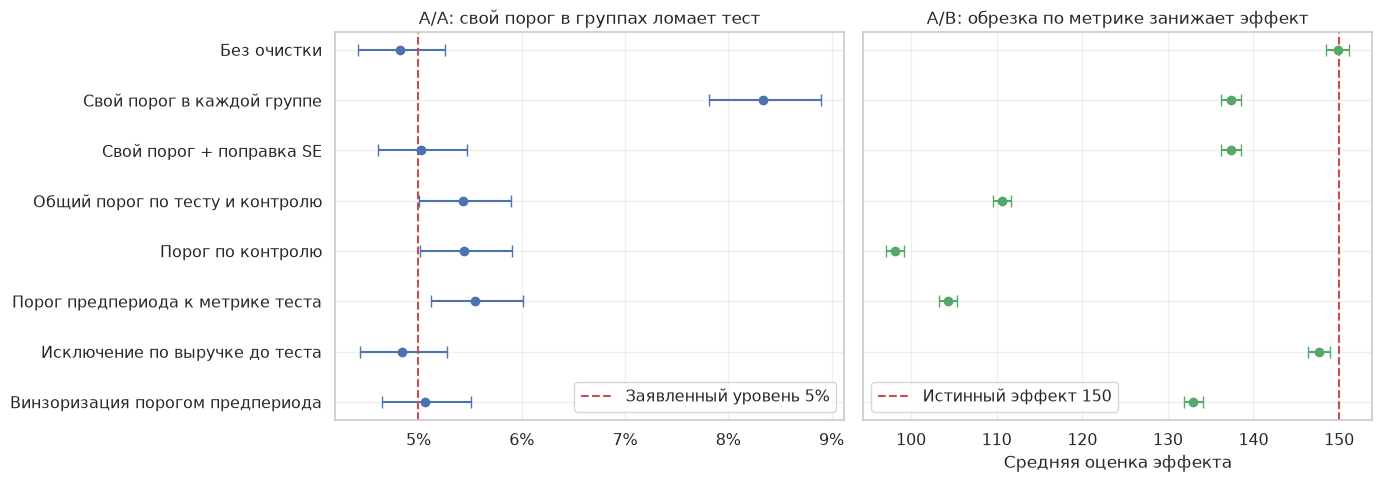

In [23]:
OUTLIER_CONFIG = {
    "n_simulations": 10_000,
    "sample_size": 1_000,
    "tail_share": 0.01,
    "lift": 1.15,  # эффект: выручка каждого пользователя выросла на 15%
}
OUTLIER_TRUE_EFFECT = 1_000 * (OUTLIER_CONFIG["lift"] - 1)


def generate_revenue(rng: np.random.Generator, size: tuple[int, int], lift: float = 1.0) -> tuple[np.ndarray, np.ndarray]:
    """Генерирует выручку пользователя до и во время эксперимента. Средняя выручка до эксперимента равна 1000."""
    activity = rng.gamma(2, 500, size)  # постоянная часть: активные пользователи тратят больше в оба периода
    return activity * rng.exponential(1, size), lift * activity * rng.exponential(1, size)


def clean_and_compare(pre_c: np.ndarray, y_c: np.ndarray, pre_t: np.ndarray, y_t: np.ndarray,
                      tail_share: float) -> dict[str, tuple[np.ndarray, np.ndarray]]:
    """Применяет способы очистки и для каждого возвращает оценку эффекта и её стандартную ошибку."""
    level = 1 - tail_share
    n = y_c.shape[1]
    q_c = np.quantile(y_c, level, axis=1, keepdims=True)
    q_t = np.quantile(y_t, level, axis=1, keepdims=True)
    q_pooled = np.quantile(np.hstack([y_c, y_t]), level, axis=1, keepdims=True)
    q_pre = np.quantile(np.hstack([pre_c, pre_t]), level, axis=1, keepdims=True)

    def compare(x_c, mask_c, x_t, mask_t):
        mean_c, var_c, n_c = masked_mean_var(x_c, mask_c)
        mean_t, var_t, n_t = masked_mean_var(x_t, mask_t)
        return mean_t - mean_c, np.sqrt(var_c / n_c + var_t / n_t)

    everyone = np.ones_like(y_c, dtype=bool)
    per_group = compare(y_c, y_c <= q_c, y_t, y_t <= q_t)
    # SE усечённого среднего, учитывающая случайность порога: дисперсия винзоризованной метрики / (1 - доля)^2
    yuen_var = (np.minimum(y_c, q_c).var(axis=1, ddof=1) + np.minimum(y_t, q_t).var(axis=1, ddof=1)) / level ** 2
    return {
        'Без очистки': compare(y_c, everyone, y_t, everyone),
        'Свой порог в каждой группе': per_group,
        'Свой порог + поправка SE': (per_group[0], np.sqrt(yuen_var / n)),
        'Общий порог по тесту и контролю': compare(y_c, y_c <= q_pooled, y_t, y_t <= q_pooled),
        'Порог по контролю': compare(y_c, y_c <= q_c, y_t, y_t <= q_c),
        'Порог предпериода к метрике теста': compare(y_c, y_c <= q_pre, y_t, y_t <= q_pre),
        'Исключение по выручке до теста': compare(y_c, pre_c <= q_pre, y_t, pre_t <= q_pre),
        'Винзоризация порогом предпериода': compare(np.minimum(y_c, q_pre), everyone, np.minimum(y_t, q_pre), everyone),
    }


def simulate_outliers(n_simulations: int, sample_size: int, tail_share: float, lift: float,
                      batch: int = 500) -> dict[str, dict[str, np.ndarray]]:
    """Прогоняет A/A и A/B и собирает оценки эффекта, SE и решения по каждому способу очистки."""
    rng = np.random.default_rng(42)
    result: dict[str, dict[str, list]] = {}
    for _ in range(n_simulations // batch):
        for key, group_lift in (('aa', 1.0), ('ab', lift)):
            pre_c, y_c = generate_revenue(rng, (batch, sample_size))
            pre_t, y_t = generate_revenue(rng, (batch, sample_size), group_lift)
            for name, (delta, se) in clean_and_compare(pre_c, y_c, pre_t, y_t, tail_share).items():
                row = result.setdefault(name, {'aa': [], 'ab': [], 'delta': [], 'se': []})
                row[key].append(z_pvalue(delta, se) < 0.05)
                if key == 'ab':
                    row['delta'].append(delta)
                    row['se'].append(se)
    return {name: {key: np.concatenate(values) for key, values in row.items()} for name, row in result.items()}


outlier_results = simulate_outliers(**OUTLIER_CONFIG)
outlier_table = pd.DataFrame({
    name: {
        'Ошибка I рода': row['aa'].mean(),
        'Мощность': row['ab'].mean(),
        'Оценка эффекта': row['delta'].mean(),
        'SD оценки': row['delta'].std(),
        'Средняя SE': row['se'].mean(),
    } for name, row in outlier_results.items()
}).T
print(f'Истинный эффект на всю аудиторию: {OUTLIER_TRUE_EFFECT:.0f}')
print(outlier_table.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
plot_rates(axes[0], {name: row['aa'] for name, row in outlier_results.items()}, 'A/A: свой порог в группах ломает тест')
names = list(outlier_results)[::-1]
axes[1].errorbar(outlier_table.loc[names, 'Оценка эффекта'], names,
                 xerr=1.96 * outlier_table.loc[names, 'SD оценки'] / np.sqrt(OUTLIER_CONFIG['n_simulations']),
                 fmt='o', color=GREEN, capsize=4)
axes[1].axvline(OUTLIER_TRUE_EFFECT, color=RED, linestyle='--', label=f'Истинный эффект {OUTLIER_TRUE_EFFECT:.0f}')
axes[1].set_title('A/B: обрезка по метрике занижает эффект')
axes[1].set_xlabel('Средняя оценка эффекта')
axes[1].legend(loc='lower left')
plt.tight_layout()
plt.show()

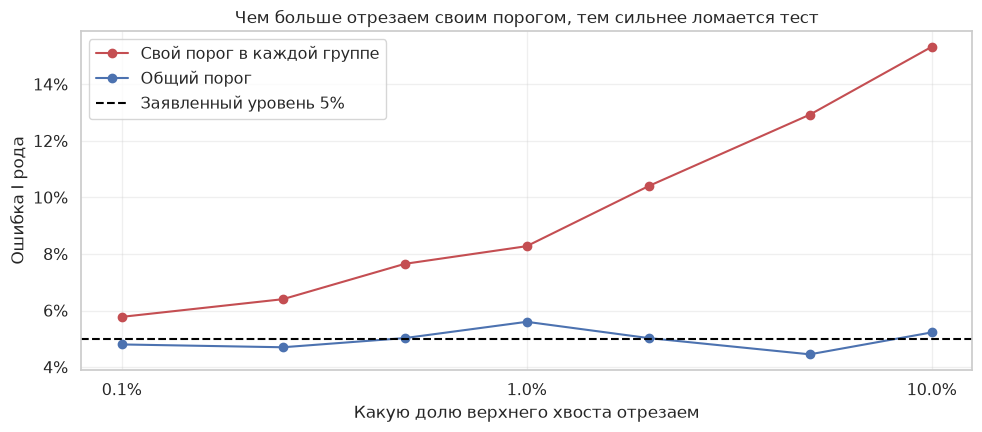

In [24]:
rng = np.random.default_rng(42)
tail_shares = np.array([0.001, 0.0025, 0.005, 0.01, 0.02, 0.05, 0.1])
per_group_fpr, pooled_fpr = [], []
for share in tail_shares:
    _, y_c = generate_revenue(rng, (4_000, 1_000))
    _, y_t = generate_revenue(rng, (4_000, 1_000))
    q_c = np.quantile(y_c, 1 - share, axis=1, keepdims=True)
    q_t = np.quantile(y_t, 1 - share, axis=1, keepdims=True)
    q_pooled = np.quantile(np.hstack([y_c, y_t]), 1 - share, axis=1, keepdims=True)
    for store, mask_c, mask_t in ((per_group_fpr, y_c <= q_c, y_t <= q_t), (pooled_fpr, y_c <= q_pooled, y_t <= q_pooled)):
        mean_c, var_c, n_c = masked_mean_var(y_c, mask_c)
        mean_t, var_t, n_t = masked_mean_var(y_t, mask_t)
        store.append(np.mean(z_pvalue(mean_t - mean_c, np.sqrt(var_c / n_c + var_t / n_t)) < 0.05))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(tail_shares, per_group_fpr, 'o-', color=RED, label='Свой порог в каждой группе')
ax.plot(tail_shares, pooled_fpr, 'o-', color=BLUE, label='Общий порог')
ax.axhline(0.05, color='black', linestyle='--', label='Заявленный уровень 5%')
ax.set_xscale('log')
ax.set_xticks([0.001, 0.01, 0.1])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1%}'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_xlabel('Какую долю верхнего хвоста отрезаем')
ax.set_ylabel('Ошибка I рода')
ax.set_title('Чем больше отрезаем своим порогом, тем сильнее ломается тест')
ax.legend()
plt.tight_layout()
plt.show()

Чем больший хвост отрезаем своим порогом в группах, тем сильнее завышена ошибка I рода. Общий порог держит α, но, как видно в таблице выше, занижает эффект. На данных с лёгкими хвостами выигрыша от очистки может и не быть: её проверяют A/A- и A/B-симуляциями на своих данных, а порог и правило фиксируют до старта.

## 8. Дизайн-док

Шаблон и рубрика ревью — [`design_doc_template.md`](design_doc_template.md). Ниже — док для кейса, собранный из расчётов разделов 3–7: числа берутся из переменных, а не руками, поэтому при смене `FROM_MEETING_1` или `DESIGN` док пересчитается.

| Поле дока | Откуда |
|---|---|
| OEC, α, MDE, N, длительность | встреча 1 и раздел 3 |
| Качество данных | раздел 4 (A/A), раздел 5 (SRM) и встреча 3 |
| Роли, поправки, guardrail, правило решения | раздел 6 |
| Ускорение | раздел 7 |
| Риски | разделы 6–7: что план **не** гарантирует |

Правило решения встреча 6 применит к результату теста как есть, без пересмотра.

In [25]:
DESIGN_DOC = {
    'гипотеза': (f'Новый чекаут поднимает конверсию в заказ (база {P_A:.1%}) больше точки безубыточности '
                 f'{100 * BE:.3f} п.п.; ошибки оплаты растут не больше чем на {100 * NI:.1f} п.п.'),
    'единица рандомизации': 'пользователь: хеш(user_id + соль теста)',
    'единица анализа': 'пользователь; средний чек — отношение, через линеаризацию',
    'OEC': (f'converted: внедряем, если p̂_B − p̂_A > θ_BE = {100 * BE:.3f} п.п. '
            f'(односторонний z-тест против θ_BE, α = {ALPHA_OEC}; против нуля α ≈ {stats.norm.sf(BE / SE1):.2f})'),
    'guardrail': (f'payment_error: non-inferiority, граница +{100 * NI:.1f} п.п., одностороннее α = {ALPHA}; '
                  f'мощность на {sp(N_PLAN)} — {GUARD_POWER:.2f}'),
    'вторичные и диагностические': f'revenue (ARPU, с CUPED), checkout_time_sec, aov; Холм, α = {ALPHA} на семейство',
    'качество данных': 'SRM (χ², p < 0.001), дубли, пользователи в обеих группах — до чтения эффектов',
    'MDE': f'{100 * MDE:.2f} п.п. (абсолютный) при мощности {POWER}',
    'сплит': f'{1 - SHARE_B:.0%}/{SHARE_B:.0%}',
    'N': N_PLAN,
    'длительность, дней': DAYS,
    'правило остановки': f'фиксированный горизонт {DAYS} дней ({WEEKS} нед.), без промежуточных решений; '
                         'досрочно — только при SRM или аварии guardrail',
    'ускорение': f'CUPED по revenue_prev28 для ARPU (дисперсия −{VAR_CUT:.0%}); для конверсии выигрыш ≈ 1%, не применяем',
    'сегменты': 'заранее: новые/вернувшиеся, платформа — только описательно, без решений',
    'правило решения': (f'внедряем, если OEC выше θ_BE и верхняя 95%-граница роста payment_error < +{100 * NI:.1f} п.п.; '
                        f'граница ≥ +{100 * NI:.1f} п.п. — «не внедряем как есть» (эскалация): внедрение приостановлено, '
                        f'разбор причины, после фикса — подтверждающий тест 50/50 на мощность '
                        f'{PLAN.loc["payment_error", "мощность"]:.1f} ({sp(N_CONFIRM)} польз., {CONFIRM_WEEKS} нед.); '
                        'OEC не выше θ_BE — «не внедряем»'),
    'риски': (f'мощность guardrail {GUARD_POWER:.2f}: даже без вреда non-inferiority не докажем в ≈ {1 - GUARD_POWER:.0%} '
              'тестов — тогда эскалация по правилу решения, не автооткат; новизна в первые дни; '
              'пересечение с другими тестами чекаута; пользователи без предпериода (ковариата = 0)'),
}

In [26]:
doc = '\n'.join(f'| {k} | {str(v).replace(chr(124), "/")} |' for k, v in DESIGN_DOC.items())
display(Markdown('#### Дизайн-док: новый чекаут\n\n| Поле | Значение |\n|---|---|\n' + doc))

#### Дизайн-док: новый чекаут

| Поле | Значение |
|---|---|
| гипотеза | Новый чекаут поднимает конверсию в заказ (база 69.9%) больше точки безубыточности 0.246 п.п.; ошибки оплаты растут не больше чем на 0.2 п.п. |
| единица рандомизации | пользователь: хеш(user_id + соль теста) |
| единица анализа | пользователь; средний чек — отношение, через линеаризацию |
| OEC | converted: внедряем, если p̂_B − p̂_A > θ_BE = 0.246 п.п. (односторонний z-тест против θ_BE, α = 0.5; против нуля α ≈ 0.24) |
| guardrail | payment_error: non-inferiority, граница +0.2 п.п., одностороннее α = 0.05; мощность на 105 000 — 0.58 |
| вторичные и диагностические | revenue (ARPU, с CUPED), checkout_time_sec, aov; Холм, α = 0.05 на семейство |
| качество данных | SRM (χ², p < 0.001), дубли, пользователи в обеих группах — до чтения эффектов |
| MDE | 0.54 п.п. (абсолютный) при мощности 0.8 |
| сплит | 80%/20% |
| N | 105000 |
| длительность, дней | 14 |
| правило остановки | фиксированный горизонт 14 дней (2 нед.), без промежуточных решений; досрочно — только при SRM или аварии guardrail |
| ускорение | CUPED по revenue_prev28 для ARPU (дисперсия −37%); для конверсии выигрыш ≈ 1%, не применяем |
| сегменты | заранее: новые/вернувшиеся, платформа — только описательно, без решений |
| правило решения | внедряем, если OEC выше θ_BE и верхняя 95%-граница роста payment_error < +0.2 п.п.; граница ≥ +0.2 п.п. — «не внедряем как есть» (эскалация): внедрение приостановлено, разбор причины, после фикса — подтверждающий тест 50/50 на мощность 0.9 (167 699 польз., 4 нед.); OEC не выше θ_BE — «не внедряем» |
| риски | мощность guardrail 0.58: даже без вреда non-inferiority не докажем в ≈ 42% тестов — тогда эскалация по правилу решения, не автооткат; новизна в первые дни; пересечение с другими тестами чекаута; пользователи без предпериода (ковариата = 0) |

**Рубрика ревью** (из шаблона): гипотеза проверяема; обе единицы названы и совпадают или указан метод; у каждой метрики роль и правило; α, мощность, MDE с единицами, $N$ и длительность согласованы; правило остановки и риски записаны до старта.

**Вопрос.** Почему правило решения — включая то, что делать, если guardrail не прошёл, — пишем в док до старта, а не решаем, когда увидим результат?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Потому что после результата любое правило становится подгонкой. Увидев «конверсия выше θ_BE, а ошибки оплаты выросли на 0.15 п.п. с верхней границей ДИ +0.3», команда захочет сказать «оценка же меньше допуска». Если правило эскалации записано заранее, спорить не о чем: граница ≥ +0.2 п.п. — «не внедряем как есть».

То же касается всего остального в доке: ковариаты CUPED, порога винзоризации, сегментов, длительности. Всё, что выбрано после того, как появились данные, увеличивает реальную ошибку I рода — это ещё один «сад расходящихся тропок». Встреча 3 проверит, что тест запущен по доку, встреча 6 применит правило как есть.

</details>

## 9. Итоги

1. **Единицы.** Рандомизируем пользователя; метрики отношения (средний чек) — через дельта-метод или линеаризацию.
2. **Вид теста и одна формула для N.** Сторонность и граница $\mu_0$ — явные параметры. Решение встречи 1 (против $\theta_{BE}$, α = 0.5) видит 0.54 п.п. за 14 дней; стандартный тест на тот же эффект шёл бы втрое дольше. Относительный MDE против абсолютного — ×2, сплит 80/20 против 50/50 — ×1.56 по пользователям (в неделях здесь разницы нет); длительность — в целых неделях. MDE, Δ и $\theta_{BE}$ — разные числа.
3. **Критерий проверяем до запуска.** Симуляция подтверждает долю решений «внедряем» (0.24 / 0.5 / 0.8), A/A на своих данных — что критерий честен на них. «n > 30» на тяжёлом хвосте не гарантия; значимый Манн–Уитни — не рост выручки.
4. **Роли метрик задают поправки.** OEC — по правилу встречи 1, guardrail — одностороннее α = 0.05 с поправкой на β, диагностические — с поправкой по семейству. Guardrail на 14 днях недобирает мощность (0.58) — это решение и риск, записанные до старта вместе с правилом эскалации.
5. **Ускорение.** Стратификация — только со стратифицированным средним. CUPED по выручке предпериода снижает дисперсию ARPU на 37% и сокращает тест на неделю, эффект не смещает. Линеаризация сама дисперсию не снижает. Выбросы — винзоризация порогом предпериода, не свой порог в группах.
6. **Дизайн-док** — вход встречи 3: по нему проверим, что тест запущен так, как задуман.

### Источники

* Kohavi, Tang, Xu. *Trustworthy Online Controlled Experiments*, 2020 — главы о метриках, SRM и снижении дисперсии.
* [Deng et al., 2013. CUPED](https://doi.org/10.1145/2433396.2433413).
* [Budylin et al., 2018. Линеаризация ratio-метрик](https://doi.org/10.1145/3159652.3159699).
* [Schultzberg et al., 2024. Risk-aware product decisions in A/B tests with multiple metrics (Spotify)](https://arxiv.org/abs/2402.11609).
* [Dmitriev et al., 2017. Metric interpretation pitfalls](https://www.microsoft.com/en-us/research/uploads/prod/2020/08/2017-08-KDDMetricInterpretationPitfalls.pdf).
* X5 Tech: [стратификация](https://habr.com/ru/companies/X5Tech/articles/596279/), [CUPED](https://habr.com/ru/companies/X5Tech/articles/780270/), [проверка валидности критерия](https://habr.com/ru/companies/X5Tech/articles/706388/); Авито: [выбросы](https://habr.com/ru/companies/avito/articles/571094/), [Манн–Уитни и средние](https://habr.com/ru/companies/avito/articles/709596/).